# Urdu agriculture model comparison: 50 wheat & cotton questions (A100)

**Edge AI for Agriculture.** This notebook compares four quantised small models with **llama.cpp** on 50 Urdu farmer questions (25 wheat, 25 cotton; 5 per category: weed management, nutrient management, fertiliser use, weather effects, plant protection).

| Model | GGUF | Quant |
|---|---|---|
| Gemma 4 E2B | `ggml-org/gemma-4-E2B-it-GGUF` | Q4_0 |
| Tiny Aya Fire | `CohereLabs/tiny-aya-fire-GGUF` | Q4_K_M |
| Qwen3.5-2B | `unsloth/Qwen3.5-2B-GGUF` | Q4_K_M |
| Qwen3-1.7B | `unsloth/Qwen3-1.7B-GGUF` | Q4_K_M |

**What gets measured**

| Requirement | How |
|---|---|
| **Answer quality** | Two large judge models (Qwen3.5-27B and Gemma-4-31B, from different families, to limit self-preference bias) score each answer 1–5 for *correctness* and *completeness* against the reference answer, and flag harmful advice. Also: chrF++ and semantic similarity (BGE-M3) to the reference. |
| **Urdu fluency** | Judge *fluency* score (1–5), share of Urdu script, Hindi/English/CJK leakage, repetition loops. |
| **Memory use** | VRAM on GPU, plus **RAM (peak RSS) in a CPU-only run**, which is the phone-relevant number. |
| **Response time** | Time to first token, tokens/s, total latency on GPU; the same on **CPU, 4 threads** (phone proxy), plus Urdu words/s. |

**Runtime:** A100 GPU (Runtime → Change runtime type → A100). Takes about 45–70 minutes and downloads about 45 GB (7 GB of test models plus 35 GB of judges).
**Outputs:** `/content/eval_results/` (zipped at the end): per-answer CSV, summary tables, charts, a side-by-side viewer, a blind sheet for human rating, and the recommended model for the demo.

## 1. Settings

In [ ]:
# ---------- test models ----------
MODELS = [
    {"name": "Gemma-4-E2B",   "repo": "ggml-org/gemma-4-E2B-it-GGUF",  "file": "gemma-4-E2B-it-Q4_0.gguf"},
    {"name": "Tiny-Aya-Fire", "repo": "CohereLabs/tiny-aya-fire-GGUF", "file": "tiny-aya-fire-q4_k_m.gguf"},
    {"name": "Qwen3.5-2B",    "repo": "unsloth/Qwen3.5-2B-GGUF",       "file": "Qwen3.5-2B-Q4_K_M.gguf"},
    {"name": "Qwen3-1.7B",    "repo": "unsloth/Qwen3-1.7B-GGUF",       "file": "Qwen3-1.7B-Q4_K_M.gguf"},
]
ALSO_RUN_Q8 = False   # True = also test the 8-bit versions (adds ~12 GB download, ~10 min)
Q8_FILES = {"Gemma-4-E2B": "gemma-4-E2B-it-Q8_0.gguf", "Tiny-Aya-Fire": "tiny-aya-fire-q8_0.gguf",
            "Qwen3.5-2B": "Qwen3.5-2B-Q8_0.gguf", "Qwen3-1.7B": "Qwen3-1.7B-Q8_0.gguf"}

# ---------- generation (same for every model) ----------
GEN = dict(temperature=0.3, top_p=0.9, top_k=40, repeat_penalty=1.1, max_tokens=512, seed=42)
CTX = 4096

# ---------- CPU-only run (phone proxy) ----------
RUN_CPU = True
CPU_THREADS = 4
N_CPU_QUESTIONS = 10        # first N questions (5 wheat + 5 cotton are picked)
CPU_MAX_TOKENS = 256

# ---------- judges ----------
JUDGES = [
    {"name": "Qwen3.5-27B", "repo": "unsloth/Qwen3.5-27B-GGUF",    "file": "Qwen3.5-27B-Q4_K_M.gguf"},
    {"name": "Gemma-4-31B", "repo": "unsloth/gemma-4-31B-it-GGUF", "file": "gemma-4-31B-it-Q4_K_M.gguf"},
]
JUDGE_PARALLEL = 4           # concurrent judge requests
RUN_SIMILARITY = True        # chrF++ and BGE-M3 similarity to the reference

PHONE_RAM_BUDGET_MB = 3000   # models above this peak RAM (CPU run) are flagged as not phone-friendly
KEEP_FILES = True            # False = delete GGUFs after use (saves disk)
SAVE_TO_DRIVE = False

MODEL_DIR, OUT = "/content/models", "/content/eval_results"

## 2. Install and build llama.cpp (CUDA, ~5 min)

In [ ]:
import os, shutil, subprocess
os.makedirs(MODEL_DIR, exist_ok=True); os.makedirs(OUT, exist_ok=True)
!nvidia-smi --query-gpu=name,memory.total --format=csv
!pip -q install -U huggingface_hub hf_transfer requests psutil pandas sacrebleu sentence-transformers scipy matplotlib openpyxl

LLAMA = "/content/llama.cpp"
SERVER, BENCH = f"{LLAMA}/build/bin/llama-server", f"{LLAMA}/build/bin/llama-bench"
if not os.path.exists(SERVER):
    !git clone --depth 1 https://github.com/ggml-org/llama.cpp {LLAMA}
    !cmake -S {LLAMA} -B {LLAMA}/build -DGGML_CUDA=ON -DCMAKE_CUDA_ARCHITECTURES=80 -DCMAKE_BUILD_TYPE=Release -DLLAMA_CURL=OFF
    !cmake --build {LLAMA}/build --config Release -j {os.cpu_count()} --target llama-server llama-bench
assert os.path.exists(SERVER), "build failed - scroll up for the error"
LLAMA_COMMIT = subprocess.run(["git", "-C", LLAMA, "log", "-1", "--format=%h %cd"], capture_output=True, text=True).stdout.strip()
print("llama.cpp", LLAMA_COMMIT, "| CPU cores:", os.cpu_count())

name, memory.total [MiB]
NVIDIA A100-SXM4-80GB, 81920 MiB
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.3, but you have pandas 3.1.1 which is incompatible.
google-colab 1.0.0 requires requests==2.32.4, but you have requests 2.34.2 which is incompatible.
dask-cudf-cu13 26.6.0 requires pandas<2.4.0,>=2.0, but you have pandas 3.1.1 which is incompatible.
datasets 4.8.5 requires huggingface-hub<2.0,>=0.25.0, but you have huggingface-hub 2.4.0 which is incompatible.
cudf-cu13 26.6.0 requires pandas<2.4.0,>=2.0, but you have pandas 3.1.1 which is incompatible.
Cloning into '/content/llama.cpp'...
remote: Enumerating objects: 4448, done.
remote: Counting objects: 100% (4448/4448), done.
remote: Compressing objects: 100% (3663/3663), done.
remote: Total 4448 (delta 828), reused 2925 (delta 698), pack-reused 0 (from 0)
Receiving

## 3. Load the 50 questions
The dataset is embedded below (`id, crop, category, query_urdu, response_urdu`). To use a different file, upload `urdu_eval_50_wheat_cotton.xlsx` to `/content` and it will be used instead.

In [ ]:
import json, pandas as pd
EMBEDDED = json.loads(r'''[{"id": "WHT-WM-02", "crop": "Wheat", "category": "Weed Management", "query_urdu": "گندم کی فصل میں ابتدائی مراحل میں جڑی بوٹیوں کو قابو میں رکھنا کیوں ضروری ہے؟", "response_urdu": "جڑی بوٹیاں سب سے زیادہ نقصان اس وقت پہنچاتی ہیں جب وہ گندم کے ابتدائی مراحل میں اس کے ساتھ مقابلہ کرتی ہیں۔ یہ وہ وقت ہوتا ہے جب فصل میں شاخیں بن رہی ہوتی ہیں اور اس کی پیداوار کی صلاحیت قائم ہو رہی ہوتی ہے۔ تحقیق سے عموماً یہ معلوم ہوتا ہے کہ گندم میں جڑی بوٹیوں کے مقابلے کا اہم دور تقریباً بیج بوائی کے بعد پہلے 30 سے 45 دنوں تک ہوتا ہے، اگرچہ یہ جڑی بوٹیوں کی کثافت اور حالات کے لحاظ سے مختلف ہو سکتا ہے۔ اس عرصے کے دوران، جڑی بوٹیاں نائٹروجن، پانی اور روشنی جذب کر لیتی ہیں جو جوان گندم کو درکار ہوتی ہے، اس لیے فصل میں کم شاخیں اور کم دانے بنتے ہیں۔ اس عرصے کے بعد جڑی بوٹیاں ہٹانے سے کچھ نقصان تو ہوتا ہے اور وہ بیجوں کو مٹی میں شامل کر دیتی ہیں، لیکن اس وقت ان پر قابو پانے سے پیداوار میں بہت کم بہتری آتی ہے۔ ابتدائی مرحلے میں جڑی بوٹیوں پر قابو پانا زیادہ مؤثر ثابت ہوتا ہے، کیونکہ جوان جڑی بوٹیاں پرانی اور سخت نباتات کے مقابلے میں جڑی بوٹی کش ادویات کے لیے زیادہ حساس ہوتی ہیں۔"}, {"id": "WHT-WM-03", "crop": "Wheat", "category": "Weed Management", "query_urdu": "گندم میں فصل اُگنے کے بعد جڑی بوٹی مار زہر کا سپرے کس وقت کرنا سب سے بہتر ہے؟", "response_urdu": "زیادہ تر وہ جڑی بوٹی کش ادویات جو گندم کے پودے کے اُبھرنے کے بعد استعمال کی جاتی ہیں، اُس وقت بہترین نتائج دیتی ہیں جب جڑی بوٹیاں جوان ہوں اور تیزی سے بڑھ رہی ہوں۔ یہ عام طور پر جڑی بوٹیوں کا 2 سے 4 پتیوں والا مرحلہ ہوتا ہے، اور آبپاشی والی گندم میں یہ اکثر بیج بوائی کے بعد تقریباً 25 سے 40 دنوں کے درمیان ہوتا ہے۔ بہت سے کسان پہلی آبپاشی کے بعد سپرے کرتے ہیں، جب مٹی میں مناسب نمی بحال ہو جاتی ہے، کیونکہ اس وقت تک جڑی بوٹیاں اُبھر چکی ہوتی ہیں اور تیزی سے بڑھ رہی ہوتی ہیں۔ بہت جلد سپرے کرنے سے وہ جڑی بوٹیاں نظر انداز ہو جاتی ہیں جو ابھی تک اُبھری نہیں ہیں۔ بہت دیر سے سپرے کرنے کا مطلب یہ ہے کہ جڑی بوٹیاں بڑی ہو چکی ہیں، وہ جڑی بوٹی کش ادویات کو بہتر طریقے سے برداشت کر سکتی ہیں، اور وہ پہلے ہی فصل کے ساتھ مقابلہ کر چکی ہیں۔ ہمیشہ پروڈکٹ کے لیبل کو چیک کریں: کچھ جڑی بوٹی کش ادویات، جیسے کہ 2,4-D، صرف گندم کی ایک مخصوص نشوونما کے مرحلے میں استعمال کرنے کے لیے محفوظ ہوتی ہیں۔"}, {"id": "WHT-WM-05", "crop": "Wheat", "category": "Weed Management", "query_urdu": "چاول اور گندم کی فصلوں والے علاقوں میں لٹل سیڈ کینری گراس (فالارِس مائنر) کو کنٹرول کرنا اتنا مشکل کیوں ہو گیا ہے؟", "response_urdu": "فالارس مائنر، چاول اور گندم کی فصلوں کے نظام میں بخوبی پنپتا ہے کیونکہ چاول کی فصل کے بعد کی گیلی اور نرم مٹی اس کے انکرن کے لیے موزوں ہوتی ہے، اور یہ گندم کے ساتھ تقریباً ایک ہی وقت میں اُگنا شروع ہو جاتا ہے۔ اس کی ابتدائی پودے گندم سے بہت ملتے جلتے ہوتے ہیں، جس کی وجہ سے دستی طور پر اسے نکالنا مشکل ہو جاتا ہے۔ ان میں فرق کرنے کا ایک طریقہ یہ ہے کہ گندم کے پتے کے نچلے حصے میں چھوٹے بالوں والے کان ہوتے ہیں، جبکہ فالارس مائنر میں یہ نہیں ہوتے اور اکثر اس کی جڑ میں گلابی رنگ کا ہلکا سا جھلک نظر آتا ہے۔ اس سے بھی بڑا مسئلہ یہ ہے کہ یہ جڑی بوٹیوں کے لیے مزاحمت پیدا کر لیتی ہے۔ برسوں تک ایک ہی قسم کی جڑی بوٹی کش دوا استعمال کرنے سے ایسی اقسام پیدا ہو گئیں جو اس دوا کے خلاف مزاحمت رکھتی ہیں۔ یہ پہلی بار شمال مغربی ہندوستان میں 1990 کی دہائی کے اوائل میں دریافت کی گئی تھیں۔ اس کے بعد سے، کچھ کلودینا فاپ، فینوکساپروپ اور سلفوسلفورون مصنوعات کے خلاف مزاحمت کی اطلاعات موصول ہوئی ہیں۔ اب اس پر قابو پانے کے لیے مختلف طریقوں سے کام کرنے والی جڑی بوٹی کش ادویات کی ضرورت ہے، جنہیں فصل کی تبدیلی، بغیر ہل چلائے کاشت، پرانی بیج بونے کی تکنیک اور مسابقتی فصلوں کی کاشت جیسی حکمت عملیوں کے ساتھ مل کر استعمال کیا جائے۔"}, {"id": "WHT-WM-08", "crop": "Wheat", "category": "Weed Management", "query_urdu": "میں گندم کی فصل میں جڑی بوٹیوں کو ہربیسائیڈز کے خلاف مزاحمت پیدا کرنے سے کیسے روک سکتا ہوں؟", "response_urdu": "جب ایک ہی قسم کی جڑی بوٹی کش دوا، یا ایک جیسے طریقے سے کام کرنے والی جڑی بوٹی کش ادویات، بار بار استعمال کی جاتی ہیں، تو جڑی بوٹیوں میں اس کے خلاف مزاحمت پیدا ہو جاتی ہے۔ ہر سپرے کے بعد، قدرتی طور پر مزاحمت رکھنے والے چند پودے بچ جاتے ہیں اور ان کی افزائش ہوتی رہتی ہے۔ اس سے بچنے کے لیے، مختلف طریقوں سے کام کرنے والی جڑی بوٹی کش ادویات کو بدل بدل کر استعمال کریں یا ملا کر استعمال کریں، جن کی شناخت بہت سی پروڈکٹ لیبل پر HRAC گروپ نمبروں سے کی جاتی ہے۔ عام گندم کے لیے استعمال ہونے والی جڑی بوٹی کش ادویات میں ACCase انحیبٹرز (گروپ 1، مثال کے طور پر کلودینا فاپ، فینوکساپروپ اور پینوکسادین)، ALS انحیبٹرز (گروپ 2، مثال کے طور پر سلفوسولفورون، میسوسولفورون اور میٹسولفورون)، مصنوعی آکسنز (گروپ 4، مثال کے طور پر 2،4-D اور MCPA) اور فوٹوسیستم II انحیبٹرز (گروپ 5، مثال کے طور پر آئسوپروٹورون اور میٹریبوزن) شامل ہیں۔ ہمیشہ تجویز کردہ مقدار میں جڑی بوٹی کش دوا استعمال کریں، کیونکہ کم مقدار میں استعمال کرنے سے جزوی طور پر مزاحمت رکھنے والی جڑی بوٹیاں بھی بچ سکتی ہیں۔ کیمیائی طریقوں کے ساتھ غیر کیمیائی طریقوں کو بھی استعمال کریں، جیسے فصل کی تبدیلی، زیادہ مقدار میں بیج کا استعمال، پرانی بیج بستر کی تکنیک، اور بیج پیدا کرنے سے پہلے ہاتھ سے جڑی بوٹیاں نکالنا۔ اپنی کٹائی کرنے والی مشینوں اور دیگر آلات کو صاف رکھیں تاکہ مزاحمت رکھنے والے جڑی بوٹیوں کے بیج ایک کھیت سے دوسرے کھیت میں منتقل نہ ہوں۔"}, {"id": "WHT-WM-09", "crop": "Wheat", "category": "Weed Management", "query_urdu": "گندم کی فصل میں جڑی بوٹیوں کو ختم کرنے والی ادویات کا سپرے کرتے وقت کیا احتیاطی تدابیر اختیار کی جائیں؟", "response_urdu": "ہر قسم کی جڑی بوٹیوں کو ختم کرنے والی دوائیوں کے سپرے کے لیے فلیٹ فین نازل استعمال کریں۔ یہ یکساں سپرے کا نمونہ فراہم کرتا ہے اور یہ وہ نازل کی قسم ہے جو عام طور پر جڑی بوٹیوں کو ختم کرنے والی دوائیوں کے لیے تجویز کی جاتی ہے۔ سپرے کرنے والے آلے کو اس طرح کیلیبریٹ کریں کہ فی ایکڑ دوا کی مقدار اور پانی کی مقدار لیبل پر درج مقدار کے مطابق ہو، اور بغیر کسی جگہ کو دو بار سپرے کیے، مسلسل رفتار سے چلتے ہوئے یا گاڑی چلاتے ہوئے سپرے کریں۔ صاف پانی استعمال کریں، کیونکہ گندی پانی بعض جڑی بوٹیوں کو ختم کرنے والی دوائیوں کی تاثیر کو کم کر سکتی ہے، خاص طور پر گلائفو سیٹ اور پیراکوئٹ کی تاثیر کم ہو سکتی ہے۔ تیز ہوا میں سپرے نہ کریں، جس کی وجہ سے دوا آس پاس کی فصلوں پر جا سکتی ہے، اور نہ ہی اس وقت سپرے کریں جب جلد ہی بارش کی توقع ہو، کیونکہ اس سے دوا جذب ہونے سے پہلے ہی دھل سکتی ہے۔ اس وقت سپرے کریں جب مٹی میں مناسب نمی ہو اور جڑی بوٹیاں تیزی سے بڑھ رہی ہوں۔ حفاظتی لباس، دستانے اور ماسک پہنیں۔ استعمال کے بعد، سپرے کرنے والے آلے کو اچھی طرح سے دھو لیں، خاص طور پر 2,4-D کے استعمال کے بعد، کیونکہ اس کی باقیات کی وجہ سے دوسری فصلوں کو نقصان پہنچ سکتا ہے۔ کیمیکلز کو محفوظ طریقے سے ذخیرہ کریں اور خالی کنٹینرز کو مناسب طریقے سے تلف کریں۔"}, {"id": "WHT-NM-01", "crop": "Wheat", "category": "Nutrient Management", "query_urdu": "گندم کی فصل میں نائٹروجن کی کمی کی علامات کیا ہیں؟", "response_urdu": "نائٹروجن پودے کے اندر آسانی سے منتقل ہو سکتا ہے، اس لیے جب اس کی کمی ہوتی ہے، تو پودا اسے پرانی پتوں سے نئے پتوں کی طرف منتقل کر دیتا ہے۔ اس کی وجہ سے کمی کی علامات سب سے پہلے پرانے، نچلے پتوں پر ظاہر ہوتی ہیں۔ یہ پتّے ہلکے سبز سے پیلے ہو جاتے ہیں، جو پہلے پتّے کے نوک سے شروع ہوتے ہیں اور پھر پتّے کے ساتھ پیچھے کی طرف بڑھتے ہیں، اور شدید صورتوں میں یہ جلد سوکھ جاتے ہیں۔ اس کی وجہ سے پوری فصل ہلکی سبز نظر آتی ہے، آہستہ بڑھتی ہے، کم شاخیں بناتی ہے، اور اس میں کم دانے ہوتے ہیں۔ ریتلی مٹی، کم органіک مواد والی مٹی، شدید بارش یا پانی کے جمع ہونے (جس کی وجہ سے غذائی اجزاء کا رس نکل جاتا ہے اور ڈینیٹری فکیشن کا نقصان ہوتا ہے)، اور جہاں نائٹروجن کی کھاد کی مقدار کم تھی یا دیر سے لگائی گئی تھی، ان جگہوں پر نائٹروجن کی کمی عام ہے۔ مٹی کا تجزیہ، پتّوں کے رنگ کا چارٹ یا پودے کے بافت کا تجزیہ اس مسئلے کی تصدیق کرنے میں مددگار ثابت ہو سکتا ہے۔"}, {"id": "WHT-NM-02", "crop": "Wheat", "category": "Nutrient Management", "query_urdu": "گندم کو فاسفورس کی ضرورت کیوں ہوتی ہے، اور مجھے کیسے معلوم ہوگا کہ آیا اس میں اس کی کمی ہے؟", "response_urdu": "فاسفورس پودے کے اندر توانائی کی منتقلی کے لیے ضروری ہے۔ یہ جڑوں کی نشوونما، شاخوں کی افزائش، ابتدائی نمو، پھولوں کی تشکیل اور دانوں کی تیاری میں مدد کرتا ہے۔ فاسفورس کی کمی والی گندم کی فصل کی نشوونما کم ہوتی ہے، اس میں کم شاخیں بنتی ہیں اور اس کی جڑوں کا نظام کمزور ہوتا ہے۔ اس کی پتیاں اکثر گہری یا بے رنگ سبز ہوتی ہیں، اور بہت سی اقسام میں ان پر جامنی یا سرخ رنگ نظر آتا ہے، خاص طور پر پرانی پتوں اور ٹھنڈے موسم میں تنوں پر۔ اس کی پختگی میں بھی تاخیر ہو سکتی ہے۔ فاسفورس مٹی میں بہت کم حرکت کرتا ہے اور یہ آسانی سے چونے والی یا تیزابی مٹی میں جذب ہو جاتا ہے، اس لیے پودے کو شروع سے ہی جڑوں کے قریب اس کی ضرورت ہوتی ہے۔ اسی لیے عام طور پر فاسفورس کو بیج بوتے وقت استعمال کیا جاتا ہے، اور اسے ترجیحاً بیج کی قطار کے قریب ڈالا یا بورا جاتا ہے۔ مٹی کا تجزیہ (مثلاً، قلوی مٹی پر اولسن پی ٹیسٹ) یہ جانچنے کا سب سے قابل اعتماد طریقہ ہے کہ آیا آپ کی مٹی میں فاسفورس کی مقدار کم ہے یا نہیں۔"}, {"id": "WHT-NM-04", "crop": "Wheat", "category": "Nutrient Management", "query_urdu": "الکلائن (کلراٹھی) زمینوں میں اُگائی جانے والی گندم میں زنک کی کمی کیوں عام ہے، اور اسے کیسے دور کیا جائے؟", "response_urdu": "جب مٹی کی پی ایچ (pH) کی سطح بڑھتی ہے، تو پودوں کے لیے زنک کی دستیابی بہت کم ہو جاتی ہے۔ کیلشیئس اور قلیائی مٹی، جیسے کہ پاکستان اور شمال مغربی ہندوستان میں پائی جاتی ہے، اس لیے اکثر اتنی زنک فراہم نہیں کر پاتی، حتیٰ کہ جب مٹی میں زنک کی کل مقدار مناسب ہو۔ کم органіک مواد، زیادہ مقدار میں فاسفورس کا استعمال، اور موسم کے شروع میں ٹھنڈی اور نم مٹی کی حالت، زنک کی کمی کو مزید بڑھا سکتی ہے۔ متاثرہ گندم کی نشوونما رک جاتی ہے اور اس کی بین النڈی (internodes) چھوٹی ہو جاتی ہیں۔ درمیانی اور جوان پتوں پر رگوں کے درمیان ہلکی پیلی رنگت یا دھبے نظر آتے ہیں، جو بعد میں بھورے ہو سکتے ہیں۔ زنک کی کمی کو عام طور پر مٹی میں زنک سلفیٹ کا استعمال کر کے دور کیا جاتا ہے، یہ عمل بیج بوتے وقت مٹی کے تجزی اور مقامی سفارشات کی بنیاد پر کیا جاتا ہے۔ پتوں پر چھڑکاؤ کے ذریعے پتلا زنک سلفیٹ محلول، جو عام طور پر تقریباً 0.5% ہوتا ہے، کا استعمال بھی فصل میں زنک کی کمی کو دور کر سکتا ہے۔ زنک سلفیٹ کو براہ راست فاسفیٹ کھادوں کے ساتھ محلول میں ملانے سے گریز کریں، کیونکہ اس سے ناقابل حل مرکبات بن سکتے ہیں۔"}, {"id": "WHT-NM-06", "crop": "Wheat", "category": "Nutrient Management", "query_urdu": "گندم کے لیے مناسب کھاد کی مقدار طے کرنے سے پہلے مٹی کی جانچ کیوں کروانی چاہیے؟", "response_urdu": "مٹی کی اقسام میں اس لحاظ سے بہت فرق ہوتا ہے کہ وہ کتنی مقدار میں نائٹروجن، فاسفورس، پوٹاشیم اور خوردنی غذائی اجزاء فراہم کر سکتی ہیں۔ صرف عام اوسط کی بنیاد پر کھاد کی تجویز کرنے سے بعض کھیتوں میں زیادہ کھاد کا استعمال ہو سکتا ہے اور بعض میں کم۔ مٹی کی جانچ سے یہ معلوم ہوتا ہے کہ اصل میں کون سے غذائی اجزاء موجود ہیں، نیز پی ایچ، نامیاتی مواد، نمکیت اور ساخت جیسی خصوصیات بھی معلوم ہوتی ہیں۔ یہ تمام چیزیں کھاد کی ضرورت اور غذائی اجزاء کے جذب ہونے کے طریقے کو متاثر کرتی ہیں۔ مٹی کی جانچ کے نتائج کی مدد سے، آپ ان غذائی اجزاء کو استعمال کر سکتے ہیں جن کی واقعی کمی ہے، ان کو چھوڑ سکتے ہیں جو پہلے سے ہی کافی ہیں، اور چھپی ہوئی مسائل جیسے زنک کی کمی، زیادہ پی ایچ یا نمکیت کو تلاش کر سکتے ہیں۔ اس سے عام طور پر پیسے بچتے ہیں، پیداوار میں اضافہ ہوتا ہے اور اضافی کھاد کے ماحول میں ہونے والے نقصان کو کم کیا جا سکتا ہے۔ نمونے کھیت کے مختلف حصوں سے مناسب گہرائی پر لیے جانے چاہئیں، عام طور پر باقاعدہ جانچ کے لیے 0 سے 15 سینٹی میٹر تک، اور پھر ان کو ملا کر ایک جامع نمونہ بنایا جانا چاہیے۔"}, {"id": "WHT-NM-07", "crop": "Wheat", "category": "Nutrient Management", "query_urdu": "گوبر کی کھاد اور نامیاتی مادہ گندم کی غذائیت میں کیا کردار ادا کرتے ہیں؟", "response_urdu": "باورچی خانے کے قریب موجود کھاد (ایف وائی ایم) اور دیگر نامیاتی مواد، نائٹروجن، فاسفورس، پوٹاشیم، سلفر اور خوردہ غذائی اجزاء فراہم کرتے ہیں۔ یہ غذائی اجزاء، ان کے تحلیل ہونے کے ساتھ ساتھ آہستہ آہستہ خارج ہوتے ہیں۔ اس سے بھی اہم بات یہ ہے کہ یہ مٹی کی ساخت، پانی کو برقرار رکھنے کی صلاحیت، ہوا کی گردش اور مائکروبیل سرگرمی کو بہتر بناتے ہیں، جس سے جڑوں کی نشوونما میں مدد ملتی ہے اور کھاد میں موجود غذائی اجزاء زیادہ آسانی سے دستیاب ہوتے ہیں۔ نامیاتی مواد، الکلی مٹی میں زنک جیسے خوردہ غذائی اجزاء کی دستیابی کو بھی بہتر بناتا ہے۔ تاہم، کھاد میں غذائی اجزاء کی مقدار نسبتاً کم اور غیر یکساں ہوتی ہے، اس لیے یہ عام طور پر اعلیٰ پیداوار والی گندم کی فصل کی مکمل غذائی ضروریات کو خود بخود پورا نہیں کر سکتی۔ بہترین نتائج عموماً اچھی طرح سے تحلیل شدہ نامیاتی کھاد کو کیمیائی کھادوں کے ساتھ ملانے سے حاصل ہوتے ہیں، اس طریقے کو متوازن غذائی انتظام کہا جاتا ہے۔ اچھی طرح سے گل سڑ جانے والی کھاد استعمال کریں، کیونکہ تازہ اور تحلیل نہ ہونے والی کھاد عارضی طور پر نائٹروجن کو جذب کر سکتی ہے اور دیمکوں کو اپنی طرف متوجہ کر سکتی ہے۔"}, {"id": "WHT-FU-01", "crop": "Wheat", "category": "Fertilizer Use", "query_urdu": "آبپاش گندم میں نائٹروجن کھاد کو کتنی قسطوں میں اور کیسے ڈالنا چاہیے؟", "response_urdu": "گندم اپنی زیادہ تر ضرورت کی نائٹروجن کی مقدار پودوں کے بڑھنے اور بالیوں کے نمودار ہونے کے درمیان اور بالیوں کے مکمل طور پر کھلنے کے مرحلے میں حاصل کرتا ہے، اور ایک بڑی مقدار میں نائٹروجن آسانی سے رسنے، بخارات بننے یا ڈینیٹری فیکیشن کے ذریعے ضائع ہو سکتی ہے۔ ان وجوہات کی بنا پر، آبپاشی والی گندم کے لیے نائٹروجن کی عام طور پر ایک ساتھ پوری مقدار دینے کے بجائے، اسے حصوں میں دیا جاتا ہے۔ ایک عام طریقہ یہ ہے کہ بیج بوتے وقت تقریباً ایک تہائی سے آدھی نائٹروجن کی مقدار دی جائے۔ باقی نائٹروجن کو ایک یا دو حصوں میں پہلی اور دوسری آبپاشی کے ساتھ دیا جاتا ہے، تقریباً جڑوں کے ابتدائی مرحلے اور بالیوں کے نمودار ہونے کے مرحلے میں۔ ہلکی اور ریتلی مٹی میں، جہاں ضائع ہونے کا امکان زیادہ ہوتا ہے، زیادہ حصوں میں نائٹروجن دینے کا مشورہ دیا جا سکتا ہے۔ فاسفورس اور پوٹاشیم کی عام طور پر بیج بوتے وقت پوری مقدار دی جاتی ہے۔ نائٹروجن کی درست مقدار اور حصوں میں دینے کا طریقہ آپ کے مقامی زرعی محکمے کی سفارشات اور مٹی کے تجزیہ کے نتائج کے مطابق ہونا چاہیے۔"}, {"id": "WHT-FU-02", "crop": "Wheat", "category": "Fertilizer Use", "query_urdu": "فاسفورس اور پوٹاشیم کی کھادیں بیج بوتے وقت کیوں استعمال کرنی چاہیے، بعد میں نہیں؟", "response_urdu": "فاسفورس زیادہ تر مٹیوں میں صرف چند ملی میٹر تک ہی منتقل ہوتا ہے، اور پوٹاشیم بھی آہستہ حرکت کرتا ہے۔ اس لیے، فصل کی نشوونما کے بعد مٹی کی سطح پر کھاد کی فراہمی کی جائے تو وہ سطح کے قریب ہی رہتی ہے اور آسانی سے فعال جڑوں والے حصے تک نہیں پہنچ پاتی۔ گندم کو جڑوں کی نشوونما اور شاخوں کی افزائش کے لیے ابتدائی مرحلے میں فاسفورس کی ضرورت ہوتی ہے، اس لیے یہ غذائی عنصر ابھرنے کے وقت جڑوں والے حصے میں موجود ہونا چاہیے۔ بیج بوتے وقت فاسفورس اور پوٹاشیم کا استعمال، خاص طور پر انہیں بیج کی قطار کے قریب مٹی میں ڈال کر، اس بات کو یقینی بناتا ہے کہ یہ غذائی عناصر پورے موسم میں جڑوں تک پہنچ سکیں۔ فاسفورس کی آخری مراحل میں سطح پر فراہمی عموماً کم مؤثر ہوتی ہے۔ یہ نائٹروجن سے مختلف ہے، جو مٹی کے پانی کے ساتھ آسانی سے منتقل ہوتا ہے اور موسم کے آخر میں اسپرے کے ذریعے فراہم کیا جا سکتا ہے۔"}, {"id": "WHT-FU-05", "crop": "Wheat", "category": "Fertilizer Use", "query_urdu": "اگر یوریا کو خشک یا تھوڑی سی نمی والی مٹی کی سطح پر بکھیر دیا جائے اور اسے بغیر آبپاشی یا مٹی میں ملائے چھوڑ دیا جائے تو کیا ہوگا؟", "response_urdu": "جب یوریا مٹی کی سطح پر موجود ہوتا ہے، تو انزائم یوریز اسے امونیم کاربونیٹ میں تبدیل کر دیتا ہے، جو کہ ہوا میں امونیا گیس کی شکل میں نکل کر مٹی سے خارج ہو جاتا ہے۔ اس نقصان کو ’واپرتالی‘ کہتے ہیں، اور یہ خاص طور پر نم مٹی کی سطح پر زیادہ ہوتا ہے جو خشک ہو رہی ہوتی ہے، یا قلوی یا چونکی مٹی میں، زیادہ درجہ حرارت پر، اور تیز ہواؤں کے دوران۔ ان حالات میں، استعمال شدہ نائٹروجن کا ایک بڑا حصہ ضائع ہو سکتا ہے، جس کی وجہ سے فصل کو وہ مقدار نہیں ملتی جس کے لیے آپ نے ادائیگی کی تھی۔ نقصان کو کم کرنے کے لیے، یوریا کو آبپاشی سے پہلے یا اس کے ساتھ استعمال کریں تاکہ پانی اسے مٹی میں لے جائے۔ متبادل کے طور پر، اسے مٹی میں ملا دیں، یا ہلکی بارش سے پہلے استعمال کریں۔ یوریز انحیبٹرز سے علاج شدہ یوریا مصنوعات بھی واپرتالی کے نقصان کو کم کر سکتی ہیں۔"}, {"id": "WHT-FU-07", "crop": "Wheat", "category": "Fertilizer Use", "query_urdu": "اگر گندم کی فصل میں بہت زیادہ مقدار میں نائٹروجن کھاد استعمال کی جائے تو کیا ہوتا ہے؟", "response_urdu": "زیادہ مقدار میں موجود نائٹروجن کی وجہ سے پودوں کی تیزی سے اور گھنی نمو ہوتی ہے، جس کے نتیجے میں لمبے اور کمزور تنے پیدا ہوتے ہیں۔ اس کی وجہ سے فصل کے گرنے کا خطرہ بڑھ جاتا ہے، خاص طور پر آبپاشی کے بعد یا جب دانہ بھرنے کا مرحلہ ہو اور اس وقت ہوا چلے۔ اس سے فصل کی پیداوار اور دانہ کی کوالٹی کم ہو جاتی ہے اور کٹائی میں مشکل پیش آتی ہے۔ گھنی اور نائٹروجن سے بھرپور پودوں کی چوٹی کی وجہ سے نمی کا ماحول پیدا ہوتا ہے، جو زنگ اور پاؤڈری ملڈیو جیسی بیماریوں کو فروغ دیتا ہے اور افیڈ کی تعداد میں اضافہ کر سکتا ہے۔ بہت زیادہ نائٹروجن کی وجہ سے فصل کی پختگی میں تاخیر ہو سکتی ہے، جس سے موسم کے آخر میں فصل زیادہ درجہ حرارت کے سامنے آ جاتی ہے۔ ایک مخصوص حد سے زیادہ نائٹروجن کی مقدار سے کوئی اضافی پیداوار نہیں ملتی اور یہ زیادہ تر رساؤ یا فضا میں تحلیل ہو جاتی ہے، جس سے پیسے ضائع ہوتے ہیں اور زیرِ زمین پانی آلود ہو جاتا ہے۔ مٹی کے تجزی اور تجویز کردہ مقدار کے مطابق نائٹروجن کا استعمال کرنے سے ان مسائل سے بچا جا سکتا ہے۔"}, {"id": "WHT-FU-09", "crop": "Wheat", "category": "Fertilizer Use", "query_urdu": "بارانی علاقوں میں گندم کو کھاد کس طرح ڈالنی چاہیے؟", "response_urdu": "بارانی علاقوں میں، مٹی میں ملانے اور اوپر سے چھڑکی جانے والی کھاد کو منتقل کرنے کے لیے کوئی آبپاشی کا انتظام نہیں ہوتا۔ موسم کے آخر میں سطح پر لگائی جانے والی نائٹروجن کی کھاد، اگر بعد میں بارش نہ ہو تو، بغیر استعمال کے رہ سکتی ہے، یا امونیا کی شکل میں ضائع ہو سکتی ہے۔ اسی وجہ سے، نائٹروجن، فاسفورس اور پوٹاشیم کی پوری مقدار عموماً بارانی گندم کی کاشت کے وقت بیج کے ساتھ مٹی میں ڈالی جاتی ہے (بیج کے کنار یا نیچے)۔ یہ مقدار عام طور پر آبپاشی والی گندم کے مقابلے میں کم ہوتی ہے، کیونکہ نمی کی کمی کی وجہ سے پیداوار کی صلاحیت محدود ہوتی ہے۔ اگر موسم کے دوران اچھی بارش ہوتی ہے، تو کچھ کسان بارش سے پہلے یا بعد میں نائٹروجن کی تھوڑی مقدار اوپر سے چھڑک دیتے ہیں۔ موسمی بارش کے بعد گہری جتائی اور مٹی کو ہموار کرنے جیسی طریقوں سے مٹی میں نمی کی مقدار کو محفوظ رکھنے سے بھی فصل کو لگائی گئی کھاد کو مؤثر طریقے سے استعمال کرنے میں مدد ملتی ہے۔"}, {"id": "WHT-WA-01", "crop": "Wheat", "category": "Weather Affects", "query_urdu": "دانے بھرنے کے دوران زیادہ درجہ حرارت گندم کی پیداوار کو کیسے متاثر کرتا ہے؟", "response_urdu": "گندم ایک ٹھنڈے موسم کی فصل ہے، اور اس کی دانے بھرنے کی عملیت گرمی کے لیے حساس ہوتی ہے۔ جب دانے بھرنے کے دوران درجہ حرارت تقریباً 30° سینٹی گریڈ سے بڑھ جاتا ہے، جسے اکثر آخری درجے کی گرمی کا تناؤ کہا جاتا ہے، تو پودا اپنی نشوونما کی رفتار بڑھا دیتا ہے اور دانے بھرنے کی مدت کم ہو جاتی ہے۔ پتے تیزی سے بوڑھے ہو جاتے ہیں اور اپنا سبز رنگ کھو دیتے ہیں، اس لیے پودا دانے بھرنے کے لیے کم مقدار میں نشاستہ پیدا کرتا ہے۔ اس کے نتیجے میں دانے چھوٹے، ہلکے اور بعض اوقات سکڑے ہوئے ہوتے ہیں، ہزار دانوں کا وزن کم ہو جاتا ہے، اور پیداوار میں کمی آتی ہے۔ گرم اور خشک ہوائیں نقصان کو مزید بڑھا دیتی ہیں۔ خطرے کو کم کرنے کے عملی طریقوں میں یہ شامل ہیں کہ مناسب وقت پر بیج بویا جائے تاکہ دانے بھرنے کا عمل گرمی کے شدید ترین دور سے پہلے ہو جائے، گرمی برداشت کرنے والی یا جلد پکنے والی اقسام کا انتخاب کیا جائے، اور دانے بھرنے کے دوران مٹی کو مناسب حد تک نمی والی رکھا جائے، کیونکہ اچھی طرح سے آبپاشی کی گئی فصل اپنے پتے کو ٹھنڈا رکھتی ہے۔"}, {"id": "WHT-WA-03", "crop": "Wheat", "category": "Weather Affects", "query_urdu": "گندم کی پچھیتی کاشت سے پیداوار کیوں کم ہو جاتی ہے؟", "response_urdu": "جب گندم کو تجویز کردہ وقت سے بعد میں بویا جاتا ہے، تو فصل کو اپنی نباتاتی نشوونما کے لیے ٹھنڈے موسم کی کم مدت ملتی ہے، اس لیے اس میں کم شاخیں بنتی ہیں اور پتے کا رقبہ بھی کم ہوتا ہے۔ اس سے بھی اہم بات یہ ہے کہ اس کی پھول اور دانہ بھرنے کی عمل کو موسم کے آخر میں زیادہ گرم موسم میں منتقل کر دیا جاتا ہے۔ اس کے بعد، آخری مرحلے میں شدید گرمی کی وجہ سے دانہ بھرنے کا عمل کم ہو جاتا ہے اور دانوں کا وزن بھی کم ہو جاتا ہے۔ پِھر، دیر سے بوئی جانے والی فصلوں کو موسم کے آخر میں گرم ہواؤں کا زیادہ خطرہ ہوتا ہے اور ان میں کچھ کیڑوں کی وجہ سے زیادہ مسائل پیدا ہو سکتے ہیں۔ جنوبی ایشیا میں کی گئی مطالعات سے پتا چلتا ہے کہ جب بوائی کا وقت بہترین وقت سے آگے بڑھایا جاتا ہے، تو پیداوار میں بتدریج کمی آتی ہے۔ اگر دیر سے بوائی سے بچا نہیں جا سکتا، تو ایسی قسم کا استعمال کریں جو دیر سے بوائی کے لیے تجویز کی گئی ہو، مقامی طور پر تجویز کردہ شرح کے مطابق بیج کی مقدار بڑھائیں، اور دانہ بھرنے کے دوران آبپاشی کا خیال رکھیں۔"}, {"id": "WHT-WA-05", "crop": "Wheat", "category": "Weather Affects", "query_urdu": "کھیت میں زیادہ پانی کھڑا رہنے سے گندم پر کیا اثرات مرتب ہوتے ہیں؟", "response_urdu": "زمین میں پانی جمع ہونے سے مٹی کے مسام پانی سے بھر جاتے ہیں اور وہ آکسیجن کو باہر نکال دیتے ہیں جس کی جڑوں کو تنفس کے لیے ضرورت ہوتی ہے۔ چند دنوں کے اندر، جڑوں کی نشوونما سست پڑ جاتی ہے یا رک جاتی ہے، اور جڑیں مر سکتی ہیں، خاص طور پر سطح کے قریب۔ پانی سے بھر جانے والی مٹی میں ڈینیٹری فیکیشن اور لیچنگ کے ذریعے نائٹروجن بھی کم ہو جاتا ہے، اس لیے پانی سے بھر جانے والی گندم میں اکثر نائٹروجن کی کمی ظاہر ہوتی ہے، جس کی وجہ سے پرانی پتیاں پیلی پڑ جاتی ہیں۔ اس سے شاخوں کی نشوونما کم ہو جاتی ہے، پودے چھوٹے رہتے ہیں، اور کچھ شاخیں یا پودے مر سکتے ہیں۔ نقصان عام طور پر ابتدائی نشوونما کے مراحل میں، گرم موسم میں، اور جب پانی کا جمع ہونا کئی دنوں تک جاری رہتا ہے، تو زیادہ ہوتا ہے۔ ناقص ہوادار مٹی میں زہریلے مرکبات بھی جمع ہو سکتے ہیں۔ خطرے کو کم کرنے کے لیے، کھیتوں کو مناسب طریقے سے ہموار کریں، بارش کی پیش گوئی ہونے پر زیادہ آبپاشی سے بچیں، سطح پر نکاسی کا انتظام کریں، اور ناقص نکاسی والی مٹی میں اونچی بستر پر پودے لگانے پر غور کریں۔"}, {"id": "WHT-WA-06", "crop": "Wheat", "category": "Weather Affects", "query_urdu": "گندم کی نشوونما کے کون سے مراحل پانی کی کمی کے لیے سب سے زیادہ حساس ہوتے ہیں؟", "response_urdu": "گندم کئی اہم مراحل میں پانی کی کمی کے حوالے سے بہت حساس ہوتی ہے۔ تاج کی جڑوں کی نشوونما (سی آر آئی)، جو آبپاشی والے جنوبی ایشیائی گندم میں بیج بونے کے تقریباً 20 سے 25 دن بعد ہوتی ہے، کو وسیع پیمانے پر آبپاشی کا سب سے اہم مرحلہ سمجھا جاتا ہے۔ اس کے بعد تناؤ کی وجہ سے جڑوں کی نشوونما اور شاخوں کی تشکیل کم ہو جاتی ہے۔ شاخوں کی نشوونما کے دوران پانی کی کمی سے دانے پیدا کرنے والی شاخوں کی تعداد کم ہو جاتی ہے۔ جوڑوں کی نشوونما اور بالیوں کے نمودار ہونے کے دوران تناؤ دانے کی نشوونما اور فی دانے دانے کی تعداد کو متاثر کرتا ہے۔ پھول آنے کا مرحلہ بہت حساس ہوتا ہے، کیونکہ اس مرحلے میں خشک سالی کی وجہ سے پولینیشن اور دانوں کی تشکیل کم ہو جاتی ہے۔ دانوں کے بھرنے کے دوران (دودھ اور آٹے کے مراحل)، پانی کی کمی سے دانوں کا وزن کم ہو جاتا ہے۔ جب آبپاشی کے لیے پانی محدود ہوتا ہے، تو سی آر آئی کے مرحلے میں اور پھر بالیوں کے نمودار ہونے یا پھول آنے کے مرحلے میں پانی دینے سے بہترین نتائج حاصل ہوتے ہیں۔ مقامی آبپاشی کے شیڈول ان اہم مراحل پر مبنی ہوتے ہیں۔"}, {"id": "WHT-WA-10", "crop": "Wheat", "category": "Weather Affects", "query_urdu": "کسان گندم کو کورے سے ہونے والے نقصان سے کیسے بچا سکتے ہیں؟", "response_urdu": "متوقع ٹھنڈی رات سے پہلے ہلکی سی آبپاشی کرنا ایک عام اور مؤثر حفاظتی تدبیر ہے۔ نمی والی مٹی خشک مٹی کی نسبت زیادہ بہتر طریقے سے حرارت کی ترسیل اور ذخیرہ کرتی ہے، اور یہ رات کے دوران اس حرارت کو خارج کرتی ہے، جس سے فصل کے قریب کی ہوا قدرے گرم رہتی ہے۔ ایسی جگہوں پر آبپاشی کرنے سے گریز کریں جہاں مٹی پہلے سے ہی پانی سے لبریز ہو۔ طویل مدت میں، سب سے اہم حفاظتی اقدام یہ ہے کہ فصل کی بوائی کی تاریخ اور قسم کا انتخاب اس طرح کیا جائے کہ حساس مراحل، جیسے کہ بالیوں کا بننا اور پھول آنا، آپ کے علاقے میں شدید سردی کی معمول کی مدت کے بعد ہوں۔ نچلے علاقوں میں واقع کھیتوں میں، جہاں سرد ہوا جمع ہوتی ہے، خطرہ زیادہ ہوتا ہے اور انہیں اضافی توجہ کی ضرورت ہو سکتی ہے۔ مناسب مقدار میں پوٹاشیم سمیت اچھی فصل کی غذائیت بھی پودوں کو سردی کے تناؤ سے بچانے میں مدد کرتی ہے۔ مقامی موسمی پیش گوئیاں اور سردی کے بارے میں انتباہات پر عمل کرنے سے آپ بروقت اقدامات کر سکتے ہیں۔"}, {"id": "WHT-PP-01", "crop": "Wheat", "category": "Plant Protection", "query_urdu": "میں گندم میں پیلی (دھاری دار) کنگی کو کیسے پہچانوں اور اس کا تدارک کیسے کروں؟", "response_urdu": "زرد زنگ، جو کہ فنگس پوکینیہ اسٹریفورمس ایف۔ ایس پی۔ ٹریٹیسی کی وجہ سے پیدا ہوتا ہے، اس سے چمکدار پیلے سے نارنجی رنگ کے پاؤڈر جیسے دانے بنتے ہیں جو پتے کی رگوں کے ساتھ لمبی لکیروں میں پھیلے ہوتے ہیں۔ جب آپ کسی متاثرہ پتے کو رگڑتے ہیں، تو پیلا پاؤڈر آپ کی انگلیوں پر آ جاتا ہے۔ یہ ٹھنڈے اور مرطوب موسم میں بہترین طریقے سے پھیلتا ہے اور اکثر ایسے مقامات پر شروع ہوتا ہے جو کھیت میں تیزی سے پھیل جاتے ہیں۔ شدید انفیکشن پتے کے رقبے کو تباہ کر دیتا ہے، جس سے دانوں کی پیداوار اور فصل کی مقدار کم ہو جاتی ہے۔ سب سے مؤثر اور معاشی حل یہ ہے کہ ایسی اقسام کی کاشت کی جائے جو موجودہ عام زنگ کی اقسام کے خلاف مزاحمت رکھتی ہوں، جیسا کہ مقامی تحقیقی اداروں کی جانب سے تجویز کیا گیا ہے۔ فصل کی باقاعدگی سے نگرانی کریں، خاص طور پر ٹھنڈے اور دھندلے موسم میں۔ اگر کسی حساس قسم پر زنگ ظاہر ہوتا ہے، تو تجویز کردہ فنگسائڈ، جیسے کہ ٹرائیزول، جیسے پروپیکونازول یا ٹیبوکونازول، لیبل پر درج مقدار کے مطابق سپرے کریں۔ اگر لیبل اور بیماری کی شدت اس کی ضرورت ظاہر کرتی ہے تو اسے دہرائیں۔"}, {"id": "WHT-PP-03", "crop": "Wheat", "category": "Plant Protection", "query_urdu": "گندم کی کانگیاری (لوز سمٹ) کیسے پھیلتی ہے، اور اس پر کیسے قابو پایا جا سکتا ہے؟", "response_urdu": "’’لوز سمت‘‘ ایک قسم کی فطر (fungus) کی وجہ سے ہوتی ہے، جس کا نام ’’اسٹیلاگو ٹریٹسی‘‘ (Ustilago tritici) ہے۔ جب فصل کی بالیاں تیار ہوتی ہیں، تو متاثرہ پودے ایسے بال تیار کرتے ہیں جن میں دانے کی جگہ کالے، پاؤڈر جیسے بیجوں کے گچھے ہوتے ہیں۔ جب یہ بیج ہوا میں بکھر جاتے ہیں، تو بال صرف ایک خالی تنہ کی صورت میں رہ جاتی ہے۔ یہ بیج ہوا کے ذریعے صحت مند پودوں کے پھولوں تک پہنچتے ہیں، جہاں یہ نشوونما پذیر بیج کو متاثر کرتے ہیں۔ اس کے بعد یہ فطر بیج کے جنین کے اندر زندہ رہتی ہے، اور یہ بالکل عام نظر آتی ہے۔ جب اس بیج کو اگلی فصل میں بویا جاتا ہے، تو یہ فطر پودے کے ساتھ بڑھتی ہے اور دوبارہ متاثرہ بال تیار کرتی ہے۔ چونکہ یہ انفیکشن بیج کے اندر ہوتا ہے، اس لیے صرف بیرونی علاج کافی نہیں ہوتے۔ اس پر قابو پانے کے لیے، تصدیق شدہ، بیماری سے پاک بیج استعمال کرنا یا ایسے سسٹمک فنگیسائیڈ (systemic fungicide) سے بیج کو محفوظ کرنا ضروری ہے جو خاص طور پر لوز سمت کے لیے رجسٹرڈ ہو، جیسے کہ کاربوکسن (carboxin) یا ٹیبوکونازول (tebuconazole)۔ متاثرہ بالوں کو ابتدائی مرحلے میں ہٹا کر تباہ کرنا، اس سے پہلے کہ بیج بکھر جائیں، اس کے پھیلاؤ کو کم کرنے میں مدد کرتا ہے۔"}, {"id": "WHT-PP-05", "crop": "Wheat", "category": "Plant Protection", "query_urdu": "سست تیلا گندم کو کیسے نقصان پہنچاتا ہے اور اس کا تدارک کب کرنا چاہیے؟", "response_urdu": "چند ایک قسم کے افیڈز گندم پر حملہ کرتے ہیں، جن میں گرین بگ (Schizaphis graminum)، انگلش گرین افیڈ (Sitobion avenae) اور برڈ چیری-اوٹ افیڈ (Rhopalosiphum padi) شامل ہیں۔ یہ پتے، تنے اور بالیوں سے رس چوستے ہیں، جس سے پودے کمزور ہو جاتے ہیں اور دانوں کی پیداوار کم ہو جاتی ہے۔ یہ چپچپا مادہ بھی خارج کرتے ہیں، جس پر سیاہ رنگ کی پھپھوندی اگتی ہے۔ کچھ اقسام بارلے یلو ڈورف وائرس کو پھیلاتے ہیں۔ افیڈ کی آبادی عموماً سرد اور خشک موسم میں موسم سرما کے آخر میں بڑھتی ہے اور اکثر قدرتی دشمنوں جیسے کہ لیڈی بیٹلز، لیس ونگز (Chrysoperla)، سر فائیڈ فلائی کے لاروا اور پرجیوی تتلیوں کے ذریعے کنٹرول میں رکھی جاتی ہے۔ باقاعدگی سے کھیت کا معائنہ کریں اور صرف اس وقت کیڑے مارنے والی دوا کا سپرے کریں جب افیڈ کی تعداد آپ کی مقامی توسیع سروس کی جانب سے تجویز کردہ معاشی حد سے تجاوز کر جائے، جو عام طور پر ایک بالی پر افیڈ کی تعداد کے طور پر بیان کی جاتی ہے۔ غیر ضروری سپرے قدرتی دشمنوں کو ختم کر دیتے ہیں اور بعد میں مزید کیڑوں کی مشکلات پیدا کر سکتے ہیں۔"}, {"id": "WHT-PP-06", "crop": "Wheat", "category": "Plant Protection", "query_urdu": "گندم کی کاشت سے پہلے بیج کو زہر آلود کرنے (سیڈ ٹریٹمنٹ) کی سفارش کیوں کی جاتی ہے؟", "response_urdu": "چند اہم گندم کی بیماریاں بیج کے ذریعے پھیلتی ہیں، جن میں لوز سمت، کورڈ سمت (عام بنٹ) اور فلیگ سمت شامل ہیں، نیز کچھ ابتدائی پودوں کی بیماریاں اور جڑوں کی سڑن بھی ان میں شامل ہیں۔ تجویز کردہ کیمیائی دوا سے بیج کو محفوظ بنانے سے یہ بیماریاں پھیلنے سے پہلے ہی ختم ہو جاتی ہیں یا ان کی نشوونما رک جاتی ہے۔ کاربوکسن یا ٹیبوکونازول جیسی سسٹمک کیمیائی دوائیں لوز سمت کو کنٹرول کر سکتی ہیں، جو بیج کے جنین کے اندر رہتی ہے۔ کیڑے مارنے والی دوائیں بیج کو استعمال کرنے سے چھوٹے پودے زمین میں موجود کیڑوں، جیسے کہ دیمک، سے محفوظ رہتے ہیں، خاص طور پر ان علاقوں میں جہاں یہ کیڑے ایک مسئلہ ہیں۔ بیج کو محفوظ بنانے کے لیے بہت کم مقدار میں کیمیائی دوا استعمال کی جاتی ہے، جو پورے کھیت پر سپرے کرنے کی نسبت زیادہ اقتصادی اور ماحول کے لیے کم نقصان دہ ہوتی ہے۔ ہمیشہ صرف محفوظ شدہ بیج کو کاشت کے لیے استعمال کریں، اسے کھانے یا جانوروں کی خوراک کے لیے استعمال نہ کریں، اور اسے استعمال کرتے وقت دستانے پہنیں۔"}, {"id": "WHT-PP-07", "crop": "Wheat", "category": "Plant Protection", "query_urdu": "گندم میں دیمک سے ہونے والے نقصان کو کیسے قابو میں لایا جا سکتا ہے؟", "response_urdu": "دیم علاقوں اور ہلکی، ریتلی مٹی میں، خاص طور پر خشک موسموں میں، دیمک ایک سنگین مسئلہ ہے۔ یہ پودوں کی جڑوں اور تنا کے نچلے حصے کو کھاتے ہیں، جس کی وجہ سے متاثرہ پودے مرجھا جاتے ہیں، خشک ہو جاتے ہیں اور آسانی سے نکالے جا سکتے ہیں، اکثر یہ نقصان جگہ جگہ نظر آتا ہے۔ یہ نقصان پودے کے ابتدائی مرحلے میں اور بعد میں بھی ہو سکتا ہے۔ اس مسئلے سے نمٹنے کے لیے ثقافتی اور کیمیائی طریقوں کا مجموعہ استعمال کیا جاتا ہے۔ صرف اچھی طرح سے گل سڑا ہوا کھاد استعمال کریں، کیونکہ بغیر گل سڑا ہوا نامیاتی مواد دیمک کو اپنی طرف متوجہ کر سکتا ہے۔ پچھلی فصلوں کے باقیات اور دیگر فضلے کو ہٹا دیں، اور جہاں ممکن ہو، وقت پر آبپاشی کریں، کیونکہ خشک مٹی دیمک کی سرگرمی کے لیے سازگار ہوتی ہے۔ کھیت کے قریب دیمک کی بستیاں تباہ کریں۔ ان علاقوں میں جہاں دیمک کے حملے کی تاریخ موجود ہے، بیج کو مقامی طور پر رجسٹرڈ کیڑے مار دوا سے محفوظ کریں، یا تجویز کردہ مٹی کی دوا استعمال کریں، اور اس کے لیے لیبل پر دی گئی ہدایات پر عمل کریں۔"}, {"id": "CTN-WM-01", "crop": "Cotton", "category": "Weed Management", "query_urdu": "کپاس کے کھیتوں میں پائی جانے والی اہم جڑی بوٹیاں کون سی ہیں؟", "response_urdu": "روئی گرم موسم میں کاشت کی جاتی ہے، اس لیے اس کی فصل میں اگنے والی بیشتر گھاسیں تیزی سے بڑھنے والی گرمیوں کی اقسام ہوتی ہیں۔ عام گھاسوں میں جنگلی چاول (ایچینوکلوآ کولونا)، کراؤ فٹ گھاس (ڈیکٹیلوکٹینیئم ایجیپٹیم)، برمودا گھاس (سائینوڈن ڈیکٹیلون) اور جانسن گھاس (سورگم ہیلیپنس) شامل ہیں۔ جامنی رنگ کی نٹسیج (سائپرس روٹنڈس، مقامی طور پر دیلا کہلاتا ہے) ایک بہت پریشان کن گھاس ہے۔ اہم چوڑی پتوں والی گھاسوں میں گھوڑے کی پورسلین (ٹرائنتھیما پورٹولا کاسٹرم، اِسٹ)، ڈیجیرا (ڈیجیرا موری کاٹا)، سور کی گھاس (امارانتھس ایس پی پی)، عام پورسلین (پورٹولاکا اولیراسیہ) اور کھیت کی بائنڈویڈ (کنولولوس آروینسس) شامل ہیں۔ بعض علاقوں، جیسے کہ جنوبی ریاست ہائے متحدہ امریکہ میں، گلائفوسیت کے خلاف مزاحمت کرنے والی پالمر امارانتھ (امارانتھس پالمیری) ایک بڑا مسئلہ ہے۔ اپنے کھیت میں موجود اہم گھاسوں کی شناخت کریں، کیونکہ گھاسوں، نٹسیج اور چوڑی پتوں والی گھاسوں کو مختلف کنٹرول کے طریقوں اور جڑی بوٹیوں کی ضرورت ہوتی ہے۔"}, {"id": "CTN-WM-02", "crop": "Cotton", "category": "Weed Management", "query_urdu": "کپاس کی ابتدائی نشوونما کے دوران جڑی بوٹیوں کی تلفی اتنی اہم کیوں ہے؟", "response_urdu": "پودے کے اُبھرنے کے بعد پہلے چند ہفتوں میں کپاس کی نشوونما آہستہ ہوتی ہے اور اسے وسیع قطاروں میں لگایا جاتا ہے، اس لیے پودوں کے درمیان کافی جگہ ہوتی ہے جہاں سورج کی روشنی پہنچتی ہے۔ گرم اور مرطوب مٹی میں موسم گرما کی فصلیں تیزی سے اگنا شروع ہو جاتی ہیں اور یہ تیزی سے جوان کپاس کے پودوں سے بڑھ کر پانی، غذائی اجزاء اور روشنی کے لیے مقابلہ کرتی ہیں۔ عام طور پر، تحقیق سے پتہ چلتا ہے کہ کپاس میں فصلوں کو کنٹرول کرنے کا اہم دور تقریباً پودے کے اُبھرنے کے بعد پہلے 6 سے 9 ہفتوں کے درمیان ہوتا ہے، اگرچہ یہ فصل کی قسم، کثافت اور جگہ کے لحاظ سے مختلف ہو سکتا ہے۔ اگر اس عرصے کے دوران فصلوں کو کنٹرول نہیں کیا جاتا ہے، تو یہ پیداوار کو بہت کم کر سکتی ہے، اور بہت زیادہ فصلوں کی موجودگی سے تقریباً پوری فصل تباہ ہو سکتی ہے۔ فصلیں کیڑوں اور بیماریوں کا بھی باعث بنتی ہیں۔ ایک بار جب کپاس کے پودے گھنے ہو جاتے ہیں، تو یہ بہت سی نئی فصلوں کو ڈھانپ لیتے ہیں، اس لیے ابتدائی ہفتوں میں کی جانے والی کوششیں بہترین نتائج دیتی ہیں۔"}, {"id": "CTN-WM-04", "crop": "Cotton", "category": "Weed Management", "query_urdu": "کپاس کی فصل میں ڈیلا (سائپرس روٹنڈس) کو کیسے کنٹرول کیا جا سکتا ہے؟", "response_urdu": "جامنی رنگ کی نٹس سیج کو کنٹرول کرنا مشکل ہے کیونکہ یہ زیادہ تر زیرِ زمین موجود جڑوں کے ذریعے پھیلتی ہے جو ایک دوسرے سے جڑے ہوتے ہیں۔ ہر جڑ پودے کی پتیاں ختم کرنے کے بعد دوبارہ اگ سکتی ہے، اور زیادہ تر ابتدائی مرحلے میں استعمال ہونے والے کیمیائی سپرے اس پر اثر انداز نہیں ہوتے۔ ایک جامع طریقہ کار سب سے بہتر نتائج دیتا ہے۔ گرم اور خشک موسم میں بیج بونے سے پہلے بار بار زمین کو جوتنے سے جڑیں سطح پر آ جاتی ہیں، جہاں وہ خشک ہو کر مر جاتی ہیں۔ بیج بونے سے پہلے، ایک ایسا کیمیائی سپرے استعمال کیا جا سکتا ہے جو پودے کے اندر جذب ہو جائے، جیسے کہ گلائفوسیت، جب نٹس سیج تیزی سے بڑھ رہی ہو اور اس میں کئی پتیاں ہوں۔ بار بار اس کی سپرے کرنے کی ضرورت پڑ سکتی ہے۔ کپاس کے پودے اگنے کے بعد، گلائفوسیت کو صرف گلائفوسیت کے اثرات کو برداشت کرنے والی اقسام پر سپرے کیا جا سکتا ہے، یا روایتی کپاس میں اسے خاص انداز میں یا ڈھال کے نیچے سپرے کیا جا سکتا ہے۔ کچھ ممالک میں نٹس سیج کے لیے کچھ اے ایل ایس-انہیبیٹر کیمیائی سپرے رجسٹرڈ ہیں۔ ایک مضبوط فصل اور ابتدائی مرحلے میں پودوں کا گھنا ہونا بھی اسے کنٹرول کرنے میں مدد کرتا ہے۔ توقع کریں کہ اسے کئی سیزن تک کنٹرول کرنے کی ضرورت پڑے گی۔"}, {"id": "CTN-WM-06", "crop": "Cotton", "category": "Weed Management", "query_urdu": "کپاس اُگنے کے بعد گھاس نما جڑی بوٹیوں کو کیسے کنٹرول کیا جا سکتا ہے؟", "response_urdu": "روئی کی فصل کے بعد اگنے والی گھاس جیسی نباتات کو کنٹرول کرنے کے لیے، اے سی سی ایس انحیبیٹر گروپ (ایچ آر اے سی گروپ 1) سے تعلق رکھنے والے مخصوص بعد از نمو گھاس کش ادویات کا استعمال کیا جا سکتا ہے۔ ان میں کوئزالفوفوپ-پی-ایتیل، ہیلوکسی فوف، فلوایزیفوف-پی-بیوٹائل اور کلیتھوڈیم شامل ہیں۔ یہ گھاس کو ختم کرتے ہیں لیکن روئی جیسی وسیع پتوں والی فصلوں کو نقصان نہیں پہنچاتے، اس لیے ان کو فصل کے اوپر سپرے کیا جا سکتا ہے، جیسا کہ لیبل پر درج ہے۔ یہ ادویات جوان گھاسوں پر بہترین کارکردگی دکھاتی ہیں، خاص طور پر جب گھاس میں 2 سے 5 پتے ہوں اور وہ تیزی سے بڑھ رہے ہوں، اور خشک سالی کی وجہ سے دباؤ کا شکار نہ ہوں۔ ان کی تاثیر اور اضافی مواد کی ضرورت مصنوعات کے لحاظ سے مختلف ہوتی ہے۔ یہ گھاس کش ادویات وسیع پتوں والی نباتات یا سیج جیسے ارغوانی نٹسایج کو کنٹرول نہیں کرتے، اس لیے ان کے لیے دیگر طریقوں کی ضرورت ہوتی ہے۔ مزاحمت کی نشوونما کو سست کرنے کے لیے، ہر موسم میں ایک ہی گروپ کی ادویات پر انحصار نہ کریں۔"}, {"id": "CTN-WM-09", "crop": "Cotton", "category": "Weed Management", "query_urdu": "گوڈی اور پودوں پر مٹی چڑھانا کپاس میں جڑی بوٹیوں کو کنٹرول کرنے میں کیسے مدد کرتے ہیں؟", "response_urdu": "بین الصفی کاشت کا مطلب ہے کہ ہاتھوں سے چلنے والے کھرپے، بیل گاڑی سے کھینچے جانے والے آلات یا ٹریکٹر سے چلنے والے ہل کا استعمال کرتے ہوئے قطاروں کے درمیان کی زمین کو جوتنا۔ اس سے قطاروں کے درمیان اُگنے والی گھاس کو جڑ سے اکھاڑ دیا جاتا ہے یا زمین میں دفن کر دیا جاتا ہے، اور یہ عمل اس وقت بہترین نتائج دیتا ہے جب گھاس چھوٹی ہو۔ اس سے مٹی کی سطح بھی ٹوٹ جاتی ہے، ہوا کی گردش بہتر ہوتی ہے اور بارش یا آبپاشی کا پانی زمین میں جذب ہونے میں مدد ملتی ہے۔ اس عمل میں مٹی کو کپاس کے پودوں کی بنیاد کی طرف منتقل کیا جاتا ہے۔ اس سے قطار میں موجود چھوٹی گھاس دفن ہو جاتی ہے، پودوں کو جھکنے سے بچایا جاتا ہے اور آبپاشی کے لیے نالیاں بنائی جاتی ہیں۔ بین الصفی کاشت عموماً پودوں کے ابتدائی مراحل میں چند بار کی جاتی ہے، اس سے پہلے کہ پودے بڑے ہو جائیں اور آلات کے گزرنے کے لیے جگہ کم پڑ جائے۔ اگر اسے پیشگی استعمال ہونے والے جڑی بوٹی کش (herbicide) اور دستی طور پر گھاس صاف کرنے کے ساتھ مل کر کیا جائے، تو یہ مؤثر اور کم لاگت میں گھاس کو کنٹرول کرنے کا ایک بہترین طریقہ ہے اور جڑی بوٹی کشوں پر انحصار کو کم کرنے میں مدد کرتا ہے۔"}, {"id": "CTN-NM-01", "crop": "Cotton", "category": "Nutrient Management", "query_urdu": "کپاس کی فصل میں نائٹروجن کی کمی کی علامات کیا ہیں؟", "response_urdu": "نائٹروجن کی وجہ سے کپاس کے پودے میں غذائی اجزاء کی نقل و حرکت ہوتی ہے، اس لیے جب نائٹروجن کی کمی ہوتی ہے، تو یہ پرانے پتوں سے بڑھتے ہوئے حصوں کی طرف منتقل ہو جاتا ہے۔ اس کی وجہ سے علامات سب سے پہلے پرانے، نچلے پتوں پر ظاہر ہوتی ہیں، جو پیلے سبز اور پھر پیلے ہو جاتے ہیں۔ بعد میں، ان میں سرخ رنگت پیدا ہو سکتی ہے اور یہ جلد جھڑ سکتے ہیں۔ نائٹروجن کی کمی والے پودے چھوٹے ہوتے ہیں، ان میں پتوں کے درمیان فاصلہ کم ہوتا ہے اور پھل دینے والی شاخیں کم ہوتی ہیں، اور اس کی وجہ سے کم تعداد میں کلیوں اور پھولوں کی پیداوار ہوتی ہے۔ اس کی وجہ سے پودے میں پھول کھلنے کا عمل بھی جلد ختم ہو سکتا ہے۔ اس کی وجہ سے پھول چھوٹے ہو سکتے ہیں، جس سے پیداوار کم ہو جاتی ہے۔ نائٹروجن کی کمی ریتلی مٹی، کم органіک مواد والی مٹی، شدید بارش یا پانی کے جمع ہونے والی مٹی، اور جہاں کھاد کی مقدار ناکافی تھی، ایسی جگہوں پر زیادہ عام ہے۔ پتی کے ڈنڈے میں موجود نائٹریٹ کی جانچ یا پتی کا تجزیہ کرنے سے اس کمی کی تصدیق کی جا سکتی ہے، اس سے پہلے کہ یہ پیداوار پر شدید اثر انداز ہو۔"}, {"id": "CTN-NM-02", "crop": "Cotton", "category": "Nutrient Management", "query_urdu": "کپاس کو پوٹاشیم کی ضرورت کیوں ہوتی ہے، اور پوٹاشیم کی کمی کی علامات کیا ہیں؟", "response_urdu": "روئی کو زیادہ مقدار میں پوٹاشیم کی ضرورت ہوتی ہے، خاص طور پر جب اس کی بالیاں تیار ہو رہی ہوں، اس وقت بالیاں پودے سے بڑی مقدار میں پوٹاشیم جذب کرتی ہیں۔ پوٹاشیم پانی کے بہاؤ، چینی کی نقل و حمل اور ریشوں کی نشوونما کے لیے اہم ہے، اور یہ ریشوں کی لمبائی، مضبوطی اور معیار کو متاثر کرتا ہے۔ جب پوٹاشیم کی کمی ہوتی ہے، تو پتے پیلے اور سفید رنگ کے دھبے دار ہو جاتے ہیں، پھر ان کا رنگ کانسی یا سرخ بھورے رنگ میں تبدیل ہو جاتا ہے، اور ان کی نوکیں اور کنارے جل جاتے ہیں اور مرجھا جاتے ہیں۔ پتے نیچے کی طرف مڑ سکتے ہیں اور جلد جھڑ سکتے ہیں۔ اس ابتدائی مرحلے میں پتوں کا مرجھانا تاریخی طور پر \"روئی کا زنگ\" کہا جاتا رہا ہے، اگرچہ یہ کوئی فطرِی بیماری نہیں ہے۔ بالیاں چھوٹی ہوتی ہیں، ممکنہ طور پر مکمل طور پر نہیں کھلتی ہیں، اور ریشوں کا معیار کم ہو جاتا ہے۔ پوٹاشیم کی کمی والے پودے بعض بیماریوں کا شکار ہونے کا زیادہ امکان رکھتے ہیں۔ مٹی کی جانچ اور پتے کا تجزیہ آپ کے کھیت کی پوٹاشیم کی ضروریات کا تعین کرنے میں مدد کرتا ہے۔"}, {"id": "CTN-NM-03", "crop": "Cotton", "category": "Nutrient Management", "query_urdu": "کپاس کی فصل میں بوران کا کیا کردار ہے، اور اس کی کمی سے کیا ہوتا ہے؟", "response_urdu": "بورون ایک خوردنی غذائی عنصر ہے جس کی ضرورت روئی کی فصل کو خلیوں کی دیوار کی تشکیل، گلابی کے انکرن، گلابی کی نالی کی نشوونما اور نشوونما پذیر کالیوں میں شکر کی منتقلی کے لیے ہوتی ہے۔ روئی کی فصل بورون کی کمی کے حوالے سے نسبتاً زیادہ حساس ہوتی ہے، خاص طور پر پھول آنے اور کالیوں کی تشکیل کے دوران۔ کمی کی علامات میں کالیوں اور جوان کالیوں کا ضرورت سے زیادہ جھڑنا، بدصورت یا چھوٹی کالیوں کا بننا، اور کالیوں کا مناسب طریقے سے نہ کھلنا شامل ہیں۔ ایک اور عام علامت یہ ہے کہ پتے کے تنے پر گہرے سبز رنگ کی پٹیاں یا حلقے نمودار ہوتے ہیں، جنہیں اکثر حلقے دار تنے کہا جاتا ہے۔ پودے کے نوک پر موجود نشوونما کے مقامات مر سکتے ہیں، جس سے پودے گھنے ہو جاتے ہیں۔ بورون کی کمی زیادہ امکان کے ساتھ ریتلی مٹی میں، جس میں نامیاتی مادے کی مقدار کم ہوتی ہے، زیادہ پی ایچ والی مٹی میں، اور خشک سالی کے دوران ہوتی ہے، کیونکہ بورون مٹی کے پانی کے ساتھ جڑوں کی طرف منتقل ہوتا ہے۔ چونکہ بورون کی کمی اور اس کی زہریلی سطح کے درمیان کا فرق بہت کم ہوتا ہے، اس لیے صرف مٹی یا ٹشو ٹیسٹ کی سفارشات کے مطابق بورون کا استعمال کریں۔"}, {"id": "CTN-NM-04", "crop": "Cotton", "category": "Nutrient Management", "query_urdu": "کپاس کے پتے سرخ کیوں ہو جاتے ہیں، اور کیا یہ ہمیشہ غذائی کمی کی وجہ سے ہوتا ہے؟", "response_urdu": "لال یا لال-جامنی رنگ کے کپاس کے پتے، سرخ رنگ کے رنگوں کی زیادتی کی وجہ سے ہوتے ہیں، جنہیں اینتھوسیانین کہتے ہیں۔ اس کی کئی وجوہات ہو سکتی ہیں، اس لیے یہ ہمیشہ غذائی قلت کی وجہ نہیں ہوتی۔ غذائی قلت سے متعلق سرخ رنگ کا پن عموماً نائٹروجن کی کمی کی وجہ سے ہوتا ہے، جس کی وجہ سے پرانے پتے سرخ ہو جاتے ہیں کیونکہ نائٹروجن ان سے نکل جاتا ہے، میگنیشیم کی کمی (پرانے پتوں پر سبز رگوں کے درمیان لال-جامنی رنگ) اور پوٹاشیم کی کمی۔ غیر غذائی وجوہات میں ٹھنڈی رات کا درجہ حرارت، خشک سالی یا پانی کی زیادتی کا تناؤ، جڑوں کو نقصان، موسم کے آخر میں زیادہ تعداد میں کلیوں کا بننا، اور پتوں کی قدرتی عمر بڑھنا شامل ہیں۔ کچھ کیڑے، جیسے کہ جسڈ، بھی پتوں کے کناروں پر سرخ رنگ کا باعث بنتے ہیں۔ وجہ کی نشاندہی کرنے کے لیے، یہ دیکھیں کہ کون سے پتے متاثر ہیں، کیڑوں کی تلاش کریں، اور کھادیں ڈالنے سے پہلے مٹی اور پتوں کے تجزیہ سے اس کی تصدیق کریں۔"}, {"id": "CTN-NM-07", "crop": "Cotton", "category": "Nutrient Management", "query_urdu": "زیادہ مقدار میں موجود نائٹروجن کا کپاس پر کیا اثر پڑتا ہے؟", "response_urdu": "زیادہ مقدار میں نائٹروجن کی وجہ سے کپاس کی پودوں کی غیر معمولی نشوونما ہوتی ہے۔ پودے بہت لمبے اور گھنے ہو جاتے ہیں اور ان کی شاخوں کے درمیان فاصلہ زیادہ ہوتا ہے، جسے اکثر تیز نشوونما کہا جاتا ہے۔ توانائی پھلوں کی بجائے پتے اور تنے میں خرچ ہوتی ہے، اس لیے پھول اور کالی کی نشوونما کم ہو سکتی ہے۔ پودے کی پختگی میں تاخیر ہوتی ہے، جس کی وجہ سے پکی ہوئی کالی سرد موسم اور آخری دنوں میں نمودار ہونے والے کیڑوں کے حملے کا شکار ہو جاتی ہے۔ گھنی اور سرسبز شاخیں فصل کے اندر نمی کی سطح کو زیادہ رکھتی ہیں، جس سے کالیوں میں سڑن پیدا ہوتی ہے، اور نرم، نائٹروجن سے بھرپور پتے چوسنے والے کیڑوں جیسے کہ وائٹ فلائی، جسڈ اور ایفیڈز کو اپنی طرف متوجہ کرتے ہیں۔ بہت لمبے پودے گرنے کے زیادہ خطرے میں ہوتے ہیں، ان پر مؤثر طریقے سے سپرے کرنا مشکل ہوتا ہے، اور ان سے پتے اتارنا اور فصل کی کٹائی کرنا بھی زیادہ مشکل ہوتا ہے۔ تجویز کردہ مقدار کے مطابق، مٹی کے تجزی اور فصل کی نگرانی کے مطابق نائٹروجن کو مختلف اوقات میں استعمال کرنے سے ان مسائل سے بچا جا سکتا ہے۔"}, {"id": "CTN-FU-01", "crop": "Cotton", "category": "Fertilizer Use", "query_urdu": "کپاس کی فصل میں بہترین نتائج کے لیے نائٹروجن کھاد کو کس طرح استعمال کیا جانا چاہیے؟", "response_urdu": "روئی کی فصل اپنی نشوونما کے دوران زیادہ تر نائٹروجن کو جذب کرتی ہے، خاص طور پر جب اس پر کلیوں کا بننا، پھول آنا اور کالیوں کی نشوونما کا مرحلہ ہوتا ہے، اس لیے نائٹروجن کو ایک ہی بار میں دینے کے بجائے مختلف اوقات میں تقسیم کر کے دینا بہتر ہوتا ہے۔ ایک عام طریقہ یہ ہے کہ بیج بوتے وقت یا اس کے قریب نائٹروجن کی ایک چھوٹی مقدار دی جائے، اور پھر باقی نائٹروجن کو کلیوں کے بننے اور پھولوں کے کھلنے کے ابتدائی اور عروج کے مراحل میں دو یا زیادہ حصوں میں تقسیم کر کے دیا جائے۔ اس طرح فصل کی ضرورت کے مطابق نائٹروجن کی فراہمی کو یقینی بنایا جا سکتا ہے اور اس سے نائٹروجن کے ضائع ہونے کا خطرہ بھی کم ہو جاتا ہے۔ ریتلی مٹی میں، نائٹروجن کو زیادہ حصوں میں تقسیم کر کے دینے کی سفارش کی جاتی ہے۔ عام طور پر، نائٹروجن کی مکمل مقدار پھولوں کے کھلنے کے عروج تک فراہم کر دی جاتی ہے، کیونکہ بعد میں دی جانے والی نائٹروجن فصل کی پختگی میں تاخیر کا باعث بن سکتی ہے۔ یوریا کو آبپاشی سے پہلے یا اس کے ساتھ دیں تاکہ پانی اسے جڑوں تک پہنچا سکے۔ کل مقدار اور درست وقت مقامی سفارشات، مٹی کے تجزیے اور فصل کی حالت کے مطابق ہونا چاہیے۔"}, {"id": "CTN-FU-02", "crop": "Cotton", "category": "Fertilizer Use", "query_urdu": "فاسفورس اور پوٹاشیم کی کھادیں کپاس کی فصل پر کب استعمال کی جائیں؟", "response_urdu": "فاسفورس کو عموماً بیج بوتے وقت یا اس سے پہلے مکمل مقدار میں استعمال کیا جانا چاہیے۔ یہ مٹی میں بہت کم حرکت کرتا ہے اور جڑوں کی نشوونما کے لیے ابتدائی مرحلے میں درکار ہوتا ہے، اس لیے اسے جڑوں کے علاقے میں رکھنا ضروری ہے، اور اس کے لیے یہ بہتر ہے کہ اسے بکھیرنے کے بجائے، بیج بوتے وقت قطاروں میں یا پٹیوں کی شکل میں ڈالا جائے۔ پوٹاشیم کو بھی عموماً درمیانی اور بھاری مٹیوں میں بیج بوتے وقت استعمال کیا جاتا ہے۔ ہلکی، ریتلی مٹیوں میں جہاں پوٹاشیم مٹی میں جذب ہو سکتا ہے، یا جہاں فصل کی نشوونما کے دوران پوٹاشیم کی زیادہ ضرورت ہوتی ہے، وہاں پوٹاشیم کی کچھ مقدار بعد میں استعمال کی جا سکتی ہے، اور بعض اوقات پودوں پر سپرے کے ذریعے بھی پوٹاشیم فراہم کیا جاتا ہے۔ دونوں غذائی عناصر کی مقدار مٹی کے تجزیہ کے نتائج کی بنیاد پر ہونی چاہیے، کیونکہ جہاں ان کی ضرورت نہیں ہوتی وہاں ان کا استعمال کرنے سے لاگت بڑھتی ہے اور پیداوار میں کوئی اضافہ نہیں ہوتا۔"}, {"id": "CTN-FU-03", "crop": "Cotton", "category": "Fertilizer Use", "query_urdu": "کپاس میں پوٹاشیم نائٹریٹ کا پتوں پر سپرے کیسے کیا جاتا ہے؟", "response_urdu": "روئی کی فصل میں پوٹاشیم کی ضرورت، بال کی نشوونما کے دوران سب سے زیادہ ہوتی ہے۔ اس مرحلے میں، جڑوں کی جانب سے پوٹاشیم کی تیزی سے اور مناسب مقدار میں فراہمی ممکن نہیں ہو پاتی، خاص طور پر خشک مٹی یا کم پوٹاشیم والی مٹی میں۔ پوٹاشیم نائٹریٹ (KNO3) کا پتے پر سپرے، عام طور پر تقریباً 1 سے 2 فیصد کی مقدار میں، پوٹاشیم اور کچھ مقدار میں نائٹروجن براہِ راست پتے کے ذریعے فراہم کر سکتا ہے۔ یہ عموماً پھول آنے اور بال کی نشوونما کے دوران کیا جاتا ہے، بعض اوقات وقفوں کے ساتھ دو یا اس سے زیادہ بار سپرے کیا جاتا ہے، جو مقامی سفارشات کے مطابق ہوتا ہے۔ تحقیق سے پتہ چلا ہے کہ اس طرح کے سپرے پتے کی قبل از وقت ہونے والی عمر رسیدہ ہونے کی عمل کو کم کرنے اور بال کے وزن اور ریشے کی کوالٹی کو بہتر بنانے میں مددگار ثابت ہو سکتے ہیں، خاص طور پر جب پوٹاشیم کی کمی ہو۔ تاہم، پتے پر کیے جانے والے سپرے صرف تھوڑی مقدار میں غذائی اجزاء فراہم کرتے ہیں۔ یہ غذائی اجزاء کی تکمیل کرتے ہیں، لیکن مٹی میں پوٹاشیم کی مناسب مقدار کی جگہ نہیں لے سکتے۔ دن کے ٹھنڈے حصوں میں سپرے کریں تاکہ پتے جلنے کا خطرہ کم ہو۔"}, {"id": "CTN-FU-07", "crop": "Cotton", "category": "Fertilizer Use", "query_urdu": "کپاس میں نائٹروجن کھاد کی آخری قسط بہت دیر سے کیوں نہیں ڈالنی چاہیے؟", "response_urdu": "روئی کی فصل کی افزائش کا کوئی خاص نمونہ نہیں ہوتا، اس کا مطلب ہے کہ جب تک اس کو کافی مقدار میں نائٹروجن، پانی اور گرم موسم دستیاب رہتا ہے، یہ مسلسل نئی پتیاں اور پھل دینے والی شاخیں پیدا کرتی رہتی ہے۔ فصل کے آخری حصے میں، جب پھول کھلنا اپنے عروج پر ہوتا ہے، اس وقت نائٹروجن کا استعمال کرنے سے نئی نباتاتی افزائش اور دیر سے پھول کھلنے کی ترغیب ملتی ہے، جس کی وجہ سے پہلے سے تیار شدہ پھولوں کی نشوونما مکمل نہیں ہو پاتی۔ اس سے فصل کی پختگی میں تاخیر ہوتی ہے۔ دیر سے کھلنے والے پھول ممکنہ طور پر درجہ حرارت کم ہونے سے پہلے مکمل طور پر تیار نہیں ہو پاتے، اور وہ موسم کے آخری حصے میں نمودار ہونے والے کیڑوں، جیسے کہ گلابی رنگ کے کیڑے اور سفید مکھی، کا شکار ہو جاتے ہیں۔ دیر سے ہونے والی تیزی سے افزائش کی وجہ سے فصل سے پتیاں ہٹانا اور اس کی کٹائی کرنا بھی مشکل ہو جاتا ہے، اس سے پھولوں کا گلنا شروع ہو سکتا ہے، اور سفید مکھی کے رس سے چپچپا روئی پیدا ہو سکتی ہے۔ ان وجوہات کی بنا پر، نائٹروجن کا استعمال عموماً پھول کھلنے کے عروج کے قریب مکمل کر دیا جاتا ہے، اور اس سلسلے میں مقامی سفارشات پر عمل کیا جاتا ہے۔"}, {"id": "CTN-FU-10", "crop": "Cotton", "category": "Fertilizer Use", "query_urdu": "کپاس میں کھاد زمین کی مناسب نمی (وتر) پر ڈالنا کیوں ضروری ہے؟", "response_urdu": "مٹی میں موجود نمی کا فصل پر اس لیے بہت اثر ہوتا ہے کہ فصل کتنی کھاد استعمال کر پائے گی۔ بہت زیادہ خشک مٹی میں کھاد ڈالنے سے وہ گھل نہیں پاتی اور جڑوں تک نہیں پہنچ پاتی، اور سطح پر موجود یوریا سے امونیا گیس کی شکل میں نائٹروجن ضائع ہو سکتی ہے۔ خشک مٹی میں کھاد کے نمکیات کی زیادہ مقدار جڑوں کو نقصان پہنچا سکتی ہے۔ پانی میں ڈوبی ہوئی مٹی میں، نائٹروجن ڈی نائٹری فیکیشن اور لیچنگ کے ذریعے ضائع ہو جاتی ہے، اور ایسی جڑوں میں جو آکسیجن سے محروم ہوتی ہیں، غذائی اجزاء اچھی طرح جذب نہیں ہو پاتے۔ پانی میں ڈوبی ہوئی کپاس کی فصل اکثر پیلی پڑ جاتی ہے، حتیٰ کہ جب کھاد ڈال دی جاتی ہے۔ بہترین طریقہ یہ ہے کہ کھاد، خاص طور پر نائٹروجن کی اضافی کھاد، اس وقت ڈالی جائے جب مٹی میں نمی ہو لیکن وہ مکمل طور پر سیر نہ ہو، عام طور پر اس سے پہلے یا آبپاشی کے ساتھ۔ تیز بارش کی توقع ہونے سے پہلے کھاد ڈالنے سے گریز کریں۔"}, {"id": "CTN-WA-01", "crop": "Cotton", "category": "Weather Affects", "query_urdu": "کپاس کے بیج کے اچھے اُگاؤ کے لیے زمین کا درجہ حرارت کتنا ہونا چاہیے؟", "response_urdu": "روئی ایک گرم موسم کی فصل ہے، اور اس کے بیج کو تیزی سے اگنے اور مضبوط پودے پیدا کرنے کے لیے گرم مٹی کی ضرورت ہوتی ہے۔ ایک عام اصول یہ ہے کہ بیج بوتے وقت مٹی کا درجہ حرارت کم از کم 18° سینٹی گریڈ (65° فارن ہائیٹ) ہونا چاہیے اور کئی دنوں تک اسی درجہ حرارت پر یا اس سے زیادہ رہنا چاہیے، اور اس دوران موسم گرم ہونا چاہیے۔ ٹھنڈی مٹی میں، انکرائی کی رفتار سست اور غیر یکساں ہوتی ہے۔ پودے کمزور ہو کر اُگتے ہیں اور فنگس جیسے پائتھیم اور رائزوکٹونیا کی وجہ سے ہونے والی بیماریوں کا زیادہ شکار ہوتے ہیں۔ بیج بونے کے فوراً بعد اچانک سردی کی لہر آنے سے پودوں کو نقصان پہنچ سکتا ہے اور ان کی نشوونما متاثر ہو سکتی ہے۔ بہت زیادہ گرم اور خشک سطح کی مٹی بھی انکرائی اور پودوں کے اُگنے میں رکاوٹ ڈال سکتی ہے، اس لیے بیج بوتے وقت مٹی میں مناسب نمی کا ہونا بھی اتنا ہی ضروری ہے۔ مقامی طور پر تجویز کردہ وقت کے اندر بیج بونے سے مناسب مٹی کا درجہ حرارت برقرار رکھنے میں مدد ملتی ہے۔"}, {"id": "CTN-WA-02", "crop": "Cotton", "category": "Weather Affects", "query_urdu": "شدید گرمی کپاس کے پھولوں اور ٹینڈوں کے ٹکنے پر کیسے اثر ڈالتی ہے؟", "response_urdu": "اگرچہ کپاس گرم موسم کی فصل ہے، لیکن پھول کھلنے کے دوران بہت زیادہ درجہ حرارت نقصان دہ ثابت ہوتا ہے۔ جب دن کا درجہ حرارت تقریباً 35 ڈگری سینٹی گریڈ سے تجاوز کر جاتا ہے، خاص طور پر جب یہ زیادہ رات کے درجہ حرارت اور کم نمی کے ساتھ مل کر اثر انداز ہوتا ہے، تو اس سے جرگ کی صلاحیت اور جرگ کی نالی کی نشوونما کم ہو جاتی ہے۔ اس کے بعد زرع (فرٹیلائزیشن) ناکام ہو جاتا ہے، اور پودا زیادہ تعداد میں کلیوں، پھولوں اور جوان بالیوں کو جھاڑ دیتا ہے۔ زیادہ رات کا درجہ حرارت سانس لینے کی رفتار کو بڑھاتا ہے، اس لیے پودا دن کے دوران پیدا ہونے والی زیادہ مقدار میں چینی کو استعمال کرتا ہے، جس سے بالیوں کی نشوونما کے لیے کم توانائی بچتی ہے۔ گرمی کا تناؤ اور خشک سالی کا مجموعہ نقصان کو اور بھی زیادہ بڑھا دیتا ہے۔ اس کے نتیجے میں بالیوں کی تعداد کم ہو جاتی ہے، بالیاں چھوٹی ہو جاتی ہیں، اور پیداوار میں کمی آتی ہے۔ گرمی کی شدید لہروں کے دوران مٹی میں مناسب نمی برقرار رکھنا، گرمی سے بچنے والی اقسام کا انتخاب کرنا، اور بوائی کی تاریخ کو اس طرح ایڈجسٹ کرنا کہ پھول کھلنے کا سب سے زیادہ دورانیہ گرم ترین وقت سے بچا جا سکے، یہ سب نقصانات کو کم کرنے میں مددگار ثابت ہو سکتا ہے۔"}, {"id": "CTN-WA-04", "crop": "Cotton", "category": "Weather Affects", "query_urdu": "زیادہ پانی جمع ہونے سے کپاس کی فصل کو کیسے نقصان پہنچتا ہے؟", "response_urdu": "روئی پانی میں زیادہ دیر رہنے سے بہت متاثر ہوتی ہے۔ جب مٹی میں پانی کی مقدار زیادہ ہو جاتی ہے، تو مٹی کے مساموں سے آکسیجن نکل جاتی ہے۔ اس کی وجہ سے جڑوں کو مناسب طریقے سے سانس لینے میں دشواری ہوتی ہے، وہ بڑھنا بند کر دیتی ہیں، اور جلد ہی مرنا شروع ہو سکتی ہیں، خاص طور پر گرم موسم میں۔ جڑوں کو پہنچنے والے نقصان سے پانی اور غذائی اجزاء جذب کرنے کی صلاحیت کم ہو جاتی ہے۔ پانی میں زیادہ دیر رہنے والی مٹی سے نائٹروجن بھی ضائع ہو جاتا ہے، جس کی وجہ سے پتے پیلے پڑنے لگتے ہیں، اور یہ عمل پرانے پتوں سے شروع ہوتا ہے۔ پانی میں زیادہ دیر رہنے والے پودے دن کے وقت مرجھا جاتے ہیں، حالانکہ مٹی میں نمی موجود ہوتی ہے، ان کے گلاب اور جوان پھول جھڑ جاتے ہیں، اور پانی نکل جانے کے بعد کچھ عرصے تک ان کی نشوونما کمزور رہتی ہے۔ طویل عرصے تک پانی میں رہنے سے پودے مر سکتے ہیں، اور اس سے جڑوں کی سڑن کی بیماریوں کو فروغ ملتا ہے۔ اس سے بچاؤ کے لیے مناسب طریقے سے زمین کو ہموار کرنا، کھیت میں نکاسی کا انتظام کرنا، بیڈ یا رج پر پودے لگانا، اور جب بارش کی پیش گوئی ہو تو زیادہ آبپاشی سے گریز کرنا شامل ہے۔"}, {"id": "CTN-WA-05", "crop": "Cotton", "category": "Weather Affects", "query_urdu": "پھول آنے اور ٹینڈے بننے کے دوران پانی کی کمی کپاس کو کیسے متاثر کرتی ہے؟", "response_urdu": "پودوں پر پھول آنے اور کالیوں کی نشوونما کا مرحلہ وہ وقت ہوتا ہے جب روئی کا پودا پانی کی کمی کے حوالے سے سب سے زیادہ حساس ہوتا ہے، کیونکہ اس وقت پودا بڑھتے ہوئے پھلوں کا زیادہ بوجھ برداشت کر رہا ہوتا ہے۔ جب اس وقت پانی کی کمی ہوتی ہے، تو پودا کالیوں، پھولوں اور جوان کالیوں کو جھاڑ کر اپنے پھلوں کا بوجھ کم کر دیتا ہے۔ جو کالیوں کو برقرار رکھا جاتا ہے، وہ چھوٹی ہو سکتی ہیں، ان میں بیج کم ہو سکتے ہیں اور روئی کی مقدار بھی کم ہو سکتی ہے۔ پانی کی کمی پودوں کی پتوں کی نشوونما اور روشنی کی ترکیب (photosynthesis) کو بھی کم کرتی ہے، اور اس سے قبل از وقت پھولوں کا خاتمہ ہو سکتا ہے، یعنی فعال پھولوں کے مرحلے کا اختتام، جس سے مجموعی پیداوار محدود ہو جاتی ہے۔ کالیوں کے بھرنے کے دوران پانی کی کمی ریشوں کی نشوونما کو متاثر کر سکتی ہے، مثال کے طور پر ریشوں کی لمبائی کو کم کر سکتی ہے۔ پھولوں کے عروج اور کالیوں کی نشوونما کے دوران بروقت آبپاشی، مٹی کی نمی کو بچانے کے لیے ملچنگ یا تحفظ کے طریقوں کا استعمال، اور آبپاشی کے درمیان طویل وقفے سے بچنے سے پیداوار کو محفوظ رکھنے میں مدد ملتی ہے۔"}, {"id": "CTN-WA-10", "crop": "Cotton", "category": "Weather Affects", "query_urdu": "کپاس کی بہت اگیتی یا بہت پچھیتی کاشت سے موسم سے متعلق مسائل کیوں پیدا ہوتے ہیں؟", "response_urdu": "بوائی کی تاریخ اس بات کا تعین کرتی ہے کہ کپاس کی افزائش کے ہر مرحلے میں کس قسم کے موسم کا سامنا کرنا پڑے گا۔ بہت جلد بوائی کرنے سے، جب مٹی ابھی گرم نہیں ہوئی ہوتی، تو انکرن سست اور غیر یکساں ہوتا ہے، پودوں کو سردی لگ سکتی ہے اور بیجوں کی بیماریاں بڑھ سکتی ہیں۔ بہت گرم علاقوں میں، اگر بوائی جلد کی جائے تو ممکن ہے کہ کپاس کے پودے گرمیوں کے دوران، جب درجہ حرارت انتہائی زیادہ ہوتا ہے، اس وقت پھول بھی پیدا کر دیں۔ اس سے پودوں پر گرمی کا اثر بڑھ سکتا ہے اور پھول جھڑ سکتے ہیں۔ بہت دیر سے بوائی کرنے سے افزائش کا دورانیہ کم ہو جاتا ہے۔ دیر سے بوائی کیے گئے پودے ایسے وقت پھولتے اور بال تیار کرتے ہیں جب درجہ حرارت کم ہو رہا ہوتا ہے اور دن چھوٹے ہوتے ہیں۔ دیر سے تیار ہونے والے بال ٹھنڈے موسم یا برف آنے سے پہلے مکمل طور پر نہیں کھل پاتے، اور فصل اکثر شدید کیڑوں کے حملے کا شکار ہو جاتی ہے، جیسے کہ گلابی رنگ کا کیڑا۔ کچھ علاقوں میں دیر سے بوائی کیے گئے پودوں کو بال کھلنے کے وقت بارش کا زیادہ خطرہ ہوتا ہے۔ آپ کے علاقے کے لیے تجویز کردہ وقت کے اندر بوائی کرنے سے ان خطرات کا توازن برقرار رہتا ہے۔"}, {"id": "CTN-PP-01", "crop": "Cotton", "category": "Plant Protection", "query_urdu": "سفید مکھی کپاس کو کیسے نقصان پہنچاتی ہے، اور اس کا تدارک کیسے کیا جائے؟", "response_urdu": "وائٹ فلائی، جسے بِمِیسیا تباسی کہتے ہیں، تین طریقوں سے کپاس کو نقصان پہنچاتی ہے۔ بالغ اور نیم بالغ کیڑے پتے کے نچلے حصے سے رس چوستے ہیں، جس سے پودا کمزور ہو جاتا ہے اور پیداوار کم ہو جاتی ہے۔ یہ چپچپا مائع خارج کرتے ہیں جو پتے اور کھلے ہوئے روئی کو ڈھانپ دیتا ہے، جس کی وجہ سے سیاہ رنگ کی پھپھوندی اور چپچپی روئی پیدا ہوتی ہے، جس کی صفائی اور کاتنا مشکل ہو جاتا ہے۔ یہ کپاس کے پتے کی پیچیدگی وائرس بھی پھیلاتے ہیں۔ اس مسئلے سے نمٹنے کے لیے کئی طریقوں کو یکجا کیا جانا چاہیے۔ جنگلی گھاسوں اور فصل کے باقیات کو ہٹا دیں، زیادہ مقدار میں نائٹروجن کے استعمال سے گریز کریں، اور اپنے علاقے کے لیے تجویز کردہ اقسام کو اگائیں۔ قدرتی دشمنوں جیسے اینکارسیا اور ایریٹموسیرس پرجیوی، لیسی ونگز اور لیڈی بیٹلز کو غیر ضروری طور پر وسیع النطاق کی کیڑے مار ادویات کے ابتدائی سپرے سے بچائیں۔ پتے کی گنتی اور پیلے رنگ کے چپچپے جالوں کے ذریعے نگرانی کریں۔ جب کیڑوں کی تعداد مقامی معاشی حد سے تجاوز کر جائے، تو چنندہ کیڑے مار ادویات جیسے کہ پائری پروکسیفین یا بوپروفیزین، یا دیگر رجسٹرڈ مصنوعات استعمال کریں، اور مزاحمت کو کم کرنے کے لیے مختلف طریقوں کو یکے بعد دیگرے استعمال کریں۔"}, {"id": "CTN-PP-02", "crop": "Cotton", "category": "Plant Protection", "query_urdu": "کپاس کے پتہ مروڑ وائرس کی بیماری کیا ہے، اور اس پر کیسے قابو پایا جا سکتا ہے؟", "response_urdu": "روئی کی پتیوں میں پیچش کی بیماری بیگوما وائرس کی وجہ سے ہوتی ہے، جیسے کہ روئی کی پتیوں میں پیچش کا ملتان وائرس۔ یہ وائرس وائٹ فلائی، بِمِیسیا تباسی کے ذریعے پھیلتا ہے۔ اس بیماری کی وجہ سے پاکستان اور شمال مغربی ہندوستان میں بڑے پیمانے پر وبائیں پھیلیں، جن میں 1990 کی دہائی کی وبا اور بعد میں بوری والا اسٹرین کی وبا شامل ہیں۔ اس بیماری کی علامات میں پتیوں کا اوپر یا نیچے کی طرف مڑنا، رگوں کا موٹا اور سیاہ ہونا، اور پتیوں کی نچلی سطح پر چھوٹی پتیوں کی طرح نمودار ہونے والی افزائش شامل ہیں۔ متاثرہ پودے کمزور ہو جاتے ہیں اور ان میں کم تعداد میں روئی پیدا ہوتی ہے، خاص طور پر اگر یہ بیماری ابتدائی مرحلے میں لگ جائے۔ متاثرہ پودوں کے لیے کوئی علاج نہیں ہے، اس لیے اس پر قابو پانے کے لیے احتیاطی تدابیر اختیار کی جاتی ہیں۔ اپنے علاقے کے لیے تجویز کردہ برداشت کرنے والی یا مزاحم اقسام کو کاشت کریں، تجویز کردہ وقت پر بیج بوئیں، وائٹ فلائی کو کنٹرول کریں، متبادل گھاس اور خود رو روئی کو ہٹا دیں، اور ابتدائی مرحلے میں متاثرہ پودوں کو اکھاڑ پھینکیں۔ جہاں ممکن ہو، روئی کو دیگر وائرس سے متاثرہ فصلوں کے ساتھ کاشت کرنے سے گریز کریں۔"}, {"id": "CTN-PP-03", "crop": "Cotton", "category": "Plant Protection", "query_urdu": "کپاس میں گلابی سنڈی کو کیسے پہچانا جائے اور اس پر کیسے قابو پایا جا سکتا ہے؟", "response_urdu": "گلابی رنگ کا کیڑا (پیکٹینوفورا گوسیپیلا) کے لاروا پھولوں، کلیوں اور بیجوں کے اندر رہتے ہوئے انہیں کھاتے ہیں، اس لیے نقصان اکثر پوشیدہ رہتا ہے۔ اس کی علامات میں یہ شامل ہیں کہ پھولوں کی پنکھڑیاں ایک لاروا کے ذریعے جڑ کر ایک گچھا بن جاتی ہیں، اور کلیوں پر چھوٹے چھوٹے سوراخ نظر آتے ہیں۔ خراب شدہ کلیوں کے اندر آپ کو گلابی رنگ کے لاروا، خراب شدہ بیج، داغ دار روئی اور ایک دوسرے سے جڑے ہوئے بیج (\"دوہرے بیج\") ملیں گے۔ متاثرہ کلیوں کے مکمل طور پر کھلنے میں دشواری ہو سکتی ہے، اور پیداوار اور روئی کی کوالٹی دونوں کم ہو جاتی ہیں۔ یہ کیڑا موسموں کے درمیان بیجوں، کھل نہ پانے والی کلیوں اور فصل کے باقیات میں لاروا کی شکل میں موجود رہ کر زندہ رہتا ہے۔ اس کی روک تھام کے لیے اس سلسلے کو توڑنا ضروری ہے۔ فصل کی کٹائی کے بعد کپاس کی شاخیں اور باقیات کو تلف کر دیں، دوبارہ فصل نہ لگائیں، اور بیج اور روئی کی باقیات کا مناسب انتظام کریں۔ مانیٹرنگ کے لیے فی رومون (گوسیپلور) کے جال استعمال کیے جاتے ہیں، اور تولید میں رکاوٹ ڈالنے کے لیے فی رومون مصنوعات کا استعمال کیا جاتا ہے۔ جب مانیٹرنگ سے معلوم ہو کہ نقصان معاشی حد سے زیادہ ہے، تو رجسٹرڈ کیڑے مار ادویات کا استعمال کریں۔ بھارت کے کچھ حصوں میں گلابی رنگ کے کیڑے نے بی ٹی کپاس کے خلاف مزاحمت پیدا کر لی ہے، اس لیے یہ غیر کیمیائی تدابیر بی ٹی کپاس میں بھی ضروری رہتی ہیں۔"}, {"id": "CTN-PP-04", "crop": "Cotton", "category": "Plant Protection", "query_urdu": "کیا اب بھی بی ٹی کپاس پر کیڑے مارنے والی دوائیوں کا سپرے کرنے کی ضرورت ہے؟", "response_urdu": "بی ٹی کپاس میں بیکٹیریم بیکلس تھورنجینس سے لیے گئے جینیات ہوتے ہیں جو کیڑے مارنے والے پروٹین پیدا کرتے ہیں، جیسے کہ بولگارڈ میں کرائی 1 اے سی اور بولگارڈ دوم میں کرائی 1 اے سی اور کرائی 2 اے بی۔ یہ پروٹین زیادہ تر کیڑوں، جیسے کہ امریکی بولورم (ہیلی کوورپا آرمیگیرا)، دھبے دار بولورم (ایاریاس ایس پی پی) اور گلابی بولورم کے لیے زہریلے ہوتے ہیں۔ بی ٹی کپاس چوسنے والے کیڑوں، جیسے کہ وائٹ فلائی، جاسیڈز، تھرپس، ایفیڈز اور میلی بگز کو کنٹرول نہیں کرتا، اس لیے ان کیڑوں کو کنٹرول کرنے کے لیے نگرانی اور حدوں کی بنیاد پر اقدامات کرنے کی ضرورت پڑ سکتی ہے۔ بی ٹی پروٹین کی سطح موسم کے آخر میں کم بھی ہو سکتی ہے، اور کچھ کیڑوں نے اس کے خلاف مزاحمت پیدا کر لی ہے۔ بھارت میں بی ٹی کپاس کے خلاف گلابی بولورم کی مزاحمت کے بارے میں بڑے پیمانے پر اطلاعات ملی ہیں۔ اس لیے بی ٹی کپاس کیڑوں کو مکمل طور پر ختم نہیں کرتا، بلکہ کیڑے مارنے والی ادویات کی ضرورت کو کم کرتا ہے۔ اس لیے باقاعدہ نگرانی، ضرورت کے مطابق پناہ دینے والی فصلیں لگانا، اور دیگر آئی پی ایم (متعلقہ کیڑوں کے لیے جامع انتظام) کے طریقوں پر عمل کرنا ضروری ہے۔"}, {"id": "CTN-PP-05", "crop": "Cotton", "category": "Plant Protection", "query_urdu": "سبز تیلا (جیسڈ) کپاس کو کیسے نقصان پہنچاتا ہے؟", "response_urdu": "جاسڈز، جنہیں کپاس کے پتے کھانے والے کیڑے بھی کہا جاتا ہے (مثلاً، امراسکا بگٹولا)، چھوٹے، شبیہہ نما، ہلکے سبز رنگ کے کیڑے ہوتے ہیں جو پریشان ہونے پر تیزی سے ایک طرف سے دوسری طرف منتقل ہوتے ہیں۔ ان کے نائڈز (larvae) اور بالغ دونوں پتے کے نچلے حصے پر موجود ہوتے ہیں، جہاں وہ رس چوستے ہیں اور زہریلا لعاب داخل کرتے ہیں۔ اس کی پہلی علامات پتے کے کناروں پر پیلا پن ہے، جس کے بعد پتے نیچے کی طرف مڑ جاتے ہیں۔ کنارے سرخ بھورے ہو جاتے ہیں اور سوکھ جاتے ہیں، یہ حالت ہوپر برن کہلاتی ہے۔ شدید حملہ پودوں کی نشوونما کو روک دیتا ہے اور ان میں پھول اور پیداوار کم ہو جاتی ہے، خاص طور پر جب یہ حملہ موسم کے شروع میں ہوتا ہے۔ بال دار پتے والے اقسام عموماً جاسڈز کے خلاف زیادہ مزاحمت کرتی ہیں، کیونکہ بال کی وجہ سے ان کیڑوں کے لیے کھانا اور انڈے دینا مشکل ہو جاتا ہے، اگرچہ بال دار پتے وائٹ فلائی کے لیے سازگار ہو سکتے ہیں۔ اس کی روک تھام میں پتے کی تعداد کی نگرانی، قدرتی دشمنوں کی حفاظت، اور صرف تب تجویز کردہ کیڑے مار ادویات کا استعمال شامل ہے جب کیڑوں کی تعداد مقامی معاشی حد سے تجاوز کر جائے۔"}]''')
up = "/content/urdu_eval_50_wheat_cotton.xlsx"
qa = pd.read_excel(up) if os.path.exists(up) else pd.DataFrame(EMBEDDED)
qa = qa[["id", "crop", "category", "query_urdu", "response_urdu"]].reset_index(drop=True)
print(len(qa), "questions"); display(qa.groupby(["crop", "category"]).size().unstack())
# CPU subset: one question per crop x category first (10), then more if N_CPU_QUESTIONS is larger
ranked = qa.assign(k=qa.groupby(["crop", "category"]).cumcount()).sort_values(["k", "crop", "category"])
CPU_IDS = ranked.id.tolist()[:N_CPU_QUESTIONS]
print("CPU subset:", CPU_IDS)

/usr/local/lib/python3.13/dist-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (


50 questions


category,Fertilizer Use,Nutrient Management,Plant Protection,Weather Affects,Weed Management
crop,,,,,
Cotton,5,5,5,5,5
Wheat,5,5,5,5,5


CPU subset: ['CTN-FU-01', 'CTN-NM-01', 'CTN-PP-01', 'CTN-WA-01', 'CTN-WM-01', 'WHT-FU-01', 'WHT-NM-01', 'WHT-PP-01', 'WHT-WA-01', 'WHT-WM-02']


## 4. Download test models

In [ ]:
os.environ["HF_HUB_ENABLE_HF_TRANSFER"] = "1"
from huggingface_hub import hf_hub_download
RUNS = [dict(m, quant=("Q4_0" if "Q4_0" in m["file"] else "Q4_K_M")) for m in MODELS]
if ALSO_RUN_Q8:
    RUNS += [dict(m, file=Q8_FILES[m["name"]], quant="Q8_0") for m in MODELS]
for r in RUNS:
    r["label"] = f'{r["name"]} [{r["quant"]}]'
    r["path"] = hf_hub_download(r["repo"], r["file"], local_dir=MODEL_DIR)
    r["size_gb"] = round(os.path.getsize(r["path"]) / 1e9, 2)
    print(f'{r["label"]:28s} {r["size_gb"]} GB')

/usr/local/lib/python3.13/dist-packages/huggingface_hub/constants.py:302: FutureWarning: The `HF_HUB_ENABLE_HF_TRANSFER` environment variable is deprecated as 'hf_transfer' is not used anymore. Please use `HF_XET_HIGH_PERFORMANCE` instead to enable high performance transfer with Xet. Visit https://huggingface.co/docs/huggingface_hub/package_reference/environment_variables#hfxethighperformance for more details.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:140: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


gemma-4-E2B-it-Q4_0.gguf: reconstructing file:   0%|          |  0.00B / 2.84GB            

gemma-4-E2B-it-Q4_0.gguf: downloading bytes:           |  0.00B            

Gemma-4-E2B [Q4_0]           2.84 GB


tiny-aya-fire-q4_k_m.gguf: reconstructing file:   0%|          |  0.00B / 2.14GB            

tiny-aya-fire-q4_k_m.gguf: downloading bytes:           |  0.00B            

... (3 outputs left out)

Qwen3.5-2B [Q4_K_M]          1.28 GB


Qwen3-1.7B-Q4_K_M.gguf: reconstructing file:   0%|          |  0.00B / 1.11GB            

Qwen3-1.7B-Q4_K_M.gguf: downloading bytes:           |  0.00B            

Qwen3-1.7B [Q4_K_M]          1.11 GB


## 5. Helpers: server, chat, metrics

In [ ]:
import re, time, threading, requests, psutil
from collections import Counter
PORT = 8090; BASE = f"http://127.0.0.1:{PORT}"

SYSTEM = ("آپ پاکستان کے کسانوں کے لیے ایک ماہر زرعی مشیر ہیں۔ کسان کے سوال کا جواب صرف اردو میں دیں۔ "
          "جواب درست، عملی اور مختصر ہو (تقریباً 100 سے 150 الفاظ)۔ اگر کسی دوا یا کھاد کی مقدار بتائیں تو فی ایکڑ بتائیں۔")

def gpu_used_mb():
    out = subprocess.run(["nvidia-smi", "--query-gpu=memory.used", "--format=csv,noheader,nounits"],
                         capture_output=True, text=True).stdout.split()
    return int(out[0]) if out else None

def start_server(path, gpu=True, ctx=CTX, parallel=1, threads=None):
    env = dict(os.environ)
    if not gpu: env["CUDA_VISIBLE_DEVICES"] = ""          # force a pure-CPU run
    cmd = [SERVER, "-m", path, "-c", str(ctx), "-np", str(parallel), "--port", str(PORT), "--jinja",
           "-ngl", "99" if gpu else "0", "-t", str(threads or os.cpu_count())]
    log = open(f"{OUT}/server.log", "a"); log.write("\n\n### " + " ".join(cmd) + "\n"); log.flush()
    p = subprocess.Popen(cmd, stdout=log, stderr=subprocess.STDOUT, env=env)
    t0 = time.time()
    while time.time() - t0 < 900:
        if p.poll() is not None:
            raise RuntimeError(open(f"{OUT}/server.log").read()[-3000:])
        try:
            if requests.get(f"{BASE}/health", timeout=2).status_code == 200:
                return p, round(time.time() - t0, 1)
        except requests.RequestException:
            pass
        time.sleep(1)
    p.kill(); raise TimeoutError("server not ready")

def stop_server(p):
    p.terminate()
    try: p.wait(30)
    except subprocess.TimeoutExpired: p.kill()
    time.sleep(3)

class RSSSampler:                                          # peak RAM of the server process
    def __init__(self, pid): self.p, self.peak, self.run = psutil.Process(pid), 0, True
    def _loop(self):
        while self.run:
            try: self.peak = max(self.peak, self.p.memory_info().rss)
            except psutil.Error: pass
            time.sleep(0.2)
    def __enter__(self): self.t = threading.Thread(target=self._loop, daemon=True); self.t.start(); return self
    def __exit__(self, *a): self.run = False; self.t.join()

THINK = re.compile(r"<think>.*?</think>", re.S)
def chat(messages, max_tokens=None, extra=None, timeout=900):
    body = {"messages": messages, "chat_template_kwargs": {"enable_thinking": False}, **GEN}
    if max_tokens: body["max_tokens"] = max_tokens
    if extra: body.update(extra)
    t0 = time.time()
    r = requests.post(f"{BASE}/v1/chat/completions", json=body, timeout=timeout)
    wall = time.time() - t0
    if r.status_code != 200 and messages[0]["role"] == "system":   # template without system role
        merged = [{"role": "user", "content": messages[0]["content"] + "\n\n" + messages[1]["content"]}] + messages[2:]
        return chat(merged, max_tokens, extra, timeout)
    r.raise_for_status(); j = r.json()
    text = THINK.sub("", j["choices"][0]["message"].get("content") or "").strip()
    t = j.get("timings", {})
    return text, {"latency_s": round(wall, 2), "ttft_s": round(t.get("prompt_ms", 0) / 1000, 3),
                  "prompt_tokens": t.get("prompt_n"), "gen_tokens": t.get("predicted_n"),
                  "gen_tok_s": round(t.get("predicted_per_second", 0), 1),
                  "finish": j["choices"][0].get("finish_reason")}

def n_tokens(text):
    return len(requests.post(f"{BASE}/tokenize", json={"content": text}, timeout=60).json()["tokens"])

URDU, DEVA = re.compile(r"[؀-ۿݐ-ݿﭐ-﷿ﹰ-﻿]"), re.compile(r"[ऀ-ॿ]")
LATIN, CJK = re.compile(r"[A-Za-z]"), re.compile(r"[぀-ヿ一-鿿가-힯]")
def script_mix(t):
    u, d, l, c = (len(rx.findall(t)) for rx in (URDU, DEVA, LATIN, CJK)); tot = (u + d + l + c) or 1
    return {"urdu_pct": round(100*u/tot, 1), "hindi_pct": round(100*d/tot, 1),
            "latin_pct": round(100*l/tot, 1), "cjk_pct": round(100*c/tot, 1)}

def is_looping(t, n=4, k=4):
    w = t.split(); c = Counter(tuple(w[i:i+n]) for i in range(len(w)-n+1))
    return bool(c) and max(c.values()) >= k

def msgs(q): return [{"role": "system", "content": SYSTEM}, {"role": "user", "content": q}]
print("ready")

ready


## 6. GPU run: all models × 50 questions
One question at a time (no batching), so latency numbers are clean.

In [ ]:
# quick smoke test: every model loads and answers one question before the long run
for r in RUNS:
    p, _ = start_server(r["path"], gpu=True)
    ans, perf = chat(msgs(qa.query_urdu[0]), max_tokens=60)
    print(f"{r['label']:26s} OK  {perf['gen_tok_s']} tok/s | {ans[:80]}")
    stop_server(p)

Gemma-4-E2B [Q4_0]         OK  100.0 tok/s | گندم کی فصل کے ابتدائی مراحل میں جڑی بوٹیوں کو قابو میں رکھنا بہت ضروری ہے۔ اس ک
Tiny-Aya-Fire [Q4_K_M]     OK  103.2 tok/s | گندم کی فصل میں ابتدائی مراحل میں جڑی بوٹیوں کو قابو میں رکھنا بہت ضروری ہے، کیو
Qwen3.5-2B [Q4_K_M]        OK  112.2 tok/s | جڑی بوٹیاں گندم کے کاشتے (Seedlings) کے لیے انتہائی ضروری ہیں۔ یہ سبزیاں پودوں ک
Qwen3-1.7B [Q4_K_M]        OK  161.7 tok/s | گندم کی فصل میں ابتدائی مراحل میں جڑی بوٹیوں کو قابو میں رکھنا ضروری ہے، کلیدی د


In [ ]:
rows, model_info = [], {}
for r in RUNS:
    print(f"\n=== {r['label']} ===")
    base = gpu_used_mb()
    p, load_s = start_server(r["path"], gpu=True)
    vram = gpu_used_mb() - base
    chat(msgs("سلام"), max_tokens=8)                                     # warm-up
    # tokenizer fertility: tokens per Urdu word over all questions + references
    sample = " ".join(qa.query_urdu) + " " + " ".join(qa.response_urdu)
    fert = round(n_tokens(sample) / len(sample.split()), 3)
    for i, q in qa.iterrows():
        try:
            ans, perf = chat(msgs(q.query_urdu))
        except Exception as e:
            ans, perf = "", {"error": str(e)[:200]}
        rows.append({"model": r["label"], "id": q.id, "crop": q.crop, "category": q.category,
                     "question": q.query_urdu, "reference": q.response_urdu, "answer": ans,
                     "words": len(ans.split()), "looping": is_looping(ans), **perf, **script_mix(ans)})
        if i % 10 == 0:
            print(f"  {i:2d} {q.id}  {perf.get('latency_s')}s  {perf.get('gen_tok_s')} tok/s  urdu {rows[-1]['urdu_pct']}%")
    model_info[r["label"]] = {"model": r["label"], "file": r["file"], "file_gb": r["size_gb"],
                              "gpu_load_s": load_s, "vram_mb": vram, "tokens_per_urdu_word": fert}
    stop_server(p)
gpu = pd.DataFrame(rows)
gpu.to_csv(f"{OUT}/answers_gpu.csv", index=False, encoding="utf-8-sig")
print("\nanswers:", len(gpu))


=== Gemma-4-E2B [Q4_0] ===
   0 WHT-WM-02  2.04s  103.0 tok/s  urdu 100.0%
  10 WHT-FU-01  2.61s  112.7 tok/s  urdu 100.0%
  20 WHT-PP-01  2.57s  110.5 tok/s  urdu 100.0%
  30 CTN-NM-01  2.19s  103.9 tok/s  urdu 99.0%
  40 CTN-WA-01  1.72s  106.3 tok/s  urdu 100.0%

=== Tiny-Aya-Fire [Q4_K_M] ===
   0 WHT-WM-02  2.13s  105.6 tok/s  urdu 100.0%
  10 WHT-FU-01  2.47s  113.8 tok/s  urdu 100.0%
  20 WHT-PP-01  2.62s  112.5 tok/s  urdu 100.0%
  30 CTN-NM-01  2.77s  104.6 tok/s  urdu 95.9%
  40 CTN-WA-01  2.0s  111.1 tok/s  urdu 99.5%

=== Qwen3.5-2B [Q4_K_M] ===
   0 WHT-WM-02  1.63s  119.3 tok/s  urdu 93.9%
  10 WHT-FU-01  2.11s  140.0 tok/s  urdu 99.2%
  20 WHT-PP-01  2.49s  138.5 tok/s  urdu 100.0%
  30 CTN-NM-01  1.19s  128.6 tok/s  urdu 100.0%
  40 CTN-WA-01  1.01s  130.2 tok/s  urdu 100.0%

=== Qwen3-1.7B [Q4_K_M] ===
   0 WHT-WM-02  1.44s  173.3 tok/s  urdu 100.0%
  10 WHT-FU-01  1.25s  174.9 tok/s  urdu 100.0%
  20 WHT-PP-01  1.92s  183.8 tok/s  urdu 100.0%
  30 CTN-NM-01  2.1s  17

## 7. CPU-only run (phone proxy): RAM and latency
The GPU is hidden (`CUDA_VISIBLE_DEVICES=''`). Each model gets the same 10 questions on `CPU_THREADS` threads. A low-end phone will be slower than a Colab CPU, but the ranking between models usually holds.

In [ ]:
cpu_rows = []
if RUN_CPU:
    for r in RUNS:
        print(f"\n=== CPU {r['label']} ===")
        p, load_s = start_server(r["path"], gpu=False, threads=CPU_THREADS)
        rss_after_load = psutil.Process(p.pid).memory_info().rss
        with RSSSampler(p.pid) as s:
            chat(msgs("سلام"), max_tokens=8)
            for qid in CPU_IDS:
                q = qa.set_index("id").loc[qid]
                ans, perf = chat(msgs(q.query_urdu), max_tokens=CPU_MAX_TOKENS)
                cpu_rows.append({"model": r["label"], "id": qid, **perf, "words": len(ans.split())})
                print(f"  {qid}  {perf['latency_s']}s  ttft {perf['ttft_s']}s  {perf['gen_tok_s']} tok/s")
        model_info[r["label"]].update({"cpu_load_s": load_s, "cpu_ram_after_load_mb": round(rss_after_load/1e6),
                                       "cpu_peak_ram_mb": round(s.peak/1e6)})
        stop_server(p)
        # llama-bench: standard prompt-processing / generation speed
        b = subprocess.run([BENCH, "-m", r["path"], "-ngl", "0", "-t", str(CPU_THREADS), "-p", "128", "-n", "64", "-o", "json"],
                           capture_output=True, text=True, env=dict(os.environ, CUDA_VISIBLE_DEVICES=""))
        try:
            for x in json.loads(b.stdout):
                key = "cpu_bench_pp128_tok_s" if x.get("n_prompt") else "cpu_bench_tg64_tok_s"
                model_info[r["label"]][key] = round(x["avg_ts"], 1)
        except Exception:
            print("llama-bench failed:", b.stderr[-300:])
cpu = pd.DataFrame(cpu_rows)
cpu.to_csv(f"{OUT}/answers_cpu_timing.csv", index=False)


=== CPU Gemma-4-E2B [Q4_0] ===
  CTN-FU-01  22.26s  ttft 0.261s  11.6 tok/s
  CTN-NM-01  18.01s  ttft 0.239s  11.7 tok/s
  CTN-PP-01  21.41s  ttft 0.251s  11.6 tok/s
  CTN-WA-01  14.3s  ttft 0.25s  11.7 tok/s
  CTN-WM-01  19.83s  ttft 0.241s  11.7 tok/s
  WHT-FU-01  22.19s  ttft 0.257s  11.6 tok/s
  WHT-NM-01  22.22s  ttft 0.239s  11.6 tok/s
  WHT-PP-01  22.41s  ttft 0.279s  11.5 tok/s
  WHT-WA-01  18.99s  ttft 0.252s  11.8 tok/s
  WHT-WM-02  22.08s  ttft 0.25s  11.7 tok/s

=== CPU Tiny-Aya-Fire [Q4_K_M] ===
  CTN-FU-01  29.58s  ttft 0.872s  8.9 tok/s
  CTN-NM-01  29.5s  ttft 0.701s  8.9 tok/s
  CTN-PP-01  29.64s  ttft 0.86s  8.9 tok/s
  CTN-WA-01  20.91s  ttft 1.011s  8.9 tok/s
  CTN-WM-01  29.49s  ttft 0.922s  8.9 tok/s
  WHT-FU-01  25.17s  ttft 0.972s  8.9 tok/s
  WHT-NM-01  25.25s  ttft 0.858s  8.9 tok/s
  WHT-PP-01  29.92s  ttft 1.132s  8.9 tok/s
  WHT-WA-01  28.3s  ttft 0.871s  8.9 tok/s
  WHT-WM-02  29.97s  ttft 1.028s  8.8 tok/s

=== CPU Qwen3.5-2B [Q4_K_M] ===
  CTN-FU-01  18

## 8. Similarity to the reference (chrF++ and BGE-M3)

In [ ]:
if RUN_SIMILARITY:
    import sacrebleu, torch
    from sentence_transformers import SentenceTransformer
    gpu["chrf"] = [round(sacrebleu.sentence_chrf(a, [ref], word_order=2).score, 1) if a else 0.0
                   for a, ref in zip(gpu.answer, gpu.reference)]
    emb = SentenceTransformer("BAAI/bge-m3", device="cuda")
    A = emb.encode(gpu.answer.fillna("").tolist(), normalize_embeddings=True, batch_size=32)
    R = emb.encode(gpu.reference.tolist(), normalize_embeddings=True, batch_size=32)
    gpu["sim_bge_m3"] = (A * R).sum(1).round(3)
    del emb; torch.cuda.empty_cache()
    display(gpu.groupby("model")[["chrf", "sim_bge_m3"]].mean().round(3))

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/123 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/15.8k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/54.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/687 [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B / 2.27GB            

... (8 outputs left out)

tokenizer.json: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/964 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/191 [00:00<?, ?B/s]

,chrf,sim_bge_m3
model,,
Gemma-4-E2B [Q4_0],28.698,0.763
Qwen3-1.7B [Q4_K_M],16.094,0.698
Qwen3.5-2B [Q4_K_M],21.648,0.707
Tiny-Aya-Fire [Q4_K_M],25.860,0.752


## 9. LLM-as-judge (two judges, blind)
Each judge sees the question, the reference answer and one candidate answer. It never sees the model name. Scores are 1–5 for **correctness, completeness, Urdu fluency, relevance**, plus a **harmful-advice** flag. Output is forced into a JSON schema.

In [ ]:
from concurrent.futures import ThreadPoolExecutor

JUDGE_SCHEMA = {"type": "object", "properties": {
    "reason": {"type": "string"},
    "correctness": {"type": "integer", "minimum": 1, "maximum": 5},
    "completeness": {"type": "integer", "minimum": 1, "maximum": 5},
    "urdu_fluency": {"type": "integer", "minimum": 1, "maximum": 5},
    "relevance": {"type": "integer", "minimum": 1, "maximum": 5},
    "harmful": {"type": "boolean"}},
    "required": ["reason", "correctness", "completeness", "urdu_fluency", "relevance", "harmful"]}

JUDGE_PROMPT = '''You are an expert agronomist for Pakistan's wheat-cotton zone (Punjab and Sindh) and a native Urdu speaker.
Grade the CANDIDATE answer to a farmer's question.

QUESTION (Urdu):
{q}

REFERENCE ANSWER (Urdu; machine-translated from an expert English answer, so its wording may contain errors - judge the agricultural facts, not its wording):
{ref}

CANDIDATE ANSWER:
{ans}

Score each from 1 to 5:
- correctness: are the facts, practices, timings and doses right for Pakistan and consistent with the reference? 5 = fully correct; 3 = partly correct with some errors; 1 = mostly wrong, invented or nonsensical.
- completeness: does it cover the key points of the reference? 5 = all key points; 1 = none.
- urdu_fluency: natural, grammatical Urdu that a Pakistani farmer would understand. Penalise repetition loops, gibberish, mixed scripts and unnecessary English.
- relevance: does it answer the question that was asked, without off-topic text?
- harmful: true only if following the advice could seriously harm the crop, the farmer or the environment (e.g. wrong or banned pesticide, dangerous dose).
"reason": at most 40 words, in English, explaining the correctness score.
Return only the JSON object.'''

def parse_judge(text):
    m = re.search(r"\{.*\}", text, re.S)
    j = json.loads(m.group(0)) if m else {}
    out = {k: int(j[k]) if k in j else None for k in ["correctness", "completeness", "urdu_fluency", "relevance"]}
    out["harmful"] = bool(j.get("harmful", False)); out["reason"] = str(j.get("reason", ""))[:300]
    return out

def judge_one(row):
    if not row.answer.strip():
        return {"correctness": 1, "completeness": 1, "urdu_fluency": 1, "relevance": 1, "harmful": False, "reason": "empty answer"}
    prompt = JUDGE_PROMPT.format(q=row.question, ref=row.reference, ans=row.answer)
    for attempt in range(3):
        try:
            txt, _ = chat([{"role": "user", "content": prompt}], max_tokens=300,
                          extra={"temperature": 0.0, "repeat_penalty": 1.0,
                                 "response_format": {"type": "json_schema", "json_schema": {"schema": JUDGE_SCHEMA}}})
            res = parse_judge(txt)
            if all(res[k] for k in ["correctness", "completeness", "urdu_fluency", "relevance"]):
                return res
        except Exception as e:
            err = str(e)
    return {"correctness": None, "completeness": None, "urdu_fluency": None, "relevance": None, "harmful": None, "reason": "judge failed"}

judged = []
for J in JUDGES:
    print(f"\n=== judge {J['name']} ===")
    path = hf_hub_download(J["repo"], J["file"], local_dir=MODEL_DIR)
    p, _ = start_server(path, gpu=True, ctx=8192 * JUDGE_PARALLEL, parallel=JUDGE_PARALLEL)
    t0 = time.time()
    with ThreadPoolExecutor(JUDGE_PARALLEL) as ex:
        res = list(ex.map(judge_one, [r for _, r in gpu.iterrows()]))
    stop_server(p)
    d = pd.DataFrame(res); d["judge"] = J["name"]; d["model"] = gpu.model.values; d["id"] = gpu.id.values
    judged.append(d)
    print(f"  judged {len(d)} answers in {time.time()-t0:.0f}s; failures: {d.correctness.isna().sum()}")
    if not KEEP_FILES: os.remove(path)
judge_long = pd.concat(judged, ignore_index=True)
judge_long.to_csv(f"{OUT}/judge_scores_long.csv", index=False, encoding="utf-8-sig")


=== judge Qwen3.5-27B ===


Qwen3.5-27B-Q4_K_M.gguf: reconstructing file:   0%|          |  0.00B / 16.7GB            

Qwen3.5-27B-Q4_K_M.gguf: downloading bytes:           |  0.00B            

  judged 200 answers in 421s; failures: 0

=== judge Gemma-4-31B ===


gemma-4-31B-it-Q4_K_M.gguf: reconstructing file:   0%|          |  0.00B / 18.3GB            

gemma-4-31B-it-Q4_K_M.gguf: downloading bytes:           |  0.00B            

  judged 200 answers in 563s; failures: 0


## 10. Combine scores and check judge agreement

In [ ]:
from scipy.stats import spearmanr, wilcoxon
CRIT = ["correctness", "completeness", "urdu_fluency", "relevance"]

# agreement between the two judges
if len(JUDGES) == 2:
    a = judge_long[judge_long.judge == JUDGES[0]["name"]].set_index(["model", "id"])
    b = judge_long[judge_long.judge == JUDGES[1]["name"]].set_index(["model", "id"])
    agree = []
    for c in CRIT:
        x, y = a[c].astype(float), b[c].astype(float); ok = x.notna() & y.notna()
        agree.append({"criterion": c, "spearman": round(spearmanr(x[ok], y[ok]).statistic, 3),
                      "exact_agree_%": round(100 * (x[ok] == y[ok]).mean(), 1),
                      "within_1_%": round(100 * ((x[ok] - y[ok]).abs() <= 1).mean(), 1)})
    agree = pd.DataFrame(agree); display(agree); agree.to_csv(f"{OUT}/judge_agreement.csv", index=False)

# per-judge model means (to spot self-preference)
display(judge_long.groupby(["judge", "model"])[CRIT].mean().round(2).unstack(0))

# average the two judges per answer
avg = judge_long.groupby(["model", "id"])[CRIT].mean().reset_index()
harm = judge_long.groupby(["model", "id"])["harmful"].apply(lambda s: bool(s.fillna(False).any())).reset_index()
reasons = judge_long.groupby(["model", "id"])["reason"].apply(lambda s: " | ".join(s)).reset_index()
res = gpu.merge(avg, on=["model", "id"]).merge(harm, on=["model", "id"]).merge(reasons, on=["model", "id"])
res["quality"] = res[["correctness", "completeness"]].mean(axis=1)            # answer quality
res["fluency"] = res["urdu_fluency"]
res["overall"] = res[CRIT].mean(axis=1)
res.to_csv(f"{OUT}/answers_scored.csv", index=False, encoding="utf-8-sig")
print("scored answers:", len(res))

,criterion,spearman,exact_agree_%,within_1_%
0,correctness,0.831,82.5,97.5
1,completeness,0.892,83.5,100.0
2,urdu_fluency,0.918,59.0,98.5
3,relevance,0.851,48.5,84.5


correctness             completeness              \
judge                  Gemma-4-31B Qwen3.5-27B  Gemma-4-31B Qwen3.5-27B   
model                                                                     
Gemma-4-E2B [Q4_0]            2.40        2.10         2.10        1.76   
Qwen3-1.7B [Q4_K_M]           1.08        1.04         1.02        1.00   
Qwen3.5-2B [Q4_K_M]           1.06        1.04         1.04        1.02   
Tiny-Aya-Fire [Q4_K_M]        1.56        1.42         1.96        1.76   

                       urdu_fluency               relevance              
judge                   Gemma-4-31B Qwen3.5-27B Gemma-4-31B Qwen3.5-27B  
model                                                                    
Gemma-4-E2B [Q4_0]             4.64        4.00        4.26        3.52  
Qwen3-1.7B [Q4_K_M]            1.22        1.14        1.86        1.52  
Qwen3.5-2B [Q4_K_M]            2.04        1.92        1.86        1.66  
Tiny-Aya-Fire [Q4_K_M]         4.30        3.76        4.44        3.18

scored answers: 200


## 11. Results table

In [ ]:
def p90(s): return s.quantile(0.9)
summ = res.groupby("model").agg(
    correctness=("correctness", "mean"), completeness=("completeness", "mean"),
    urdu_fluency=("urdu_fluency", "mean"), relevance=("relevance", "mean"),
    answer_quality=("quality", "mean"), overall=("overall", "mean"),
    harmful_answers=("harmful", "sum"), looping_answers=("looping", "sum"),
    urdu_script_pct=("urdu_pct", "mean"), hindi_leak=("hindi_pct", lambda s: int((s > 2).sum())),
    truncated=("finish", lambda s: int((s == "length").sum())),
    avg_words=("words", "mean"),
    gpu_latency_median_s=("latency_s", "median"), gpu_latency_p90_s=("latency_s", p90),
    gpu_ttft_median_s=("ttft_s", "median"), gpu_gen_tok_s=("gen_tok_s", "mean"),
    **({"chrf": ("chrf", "mean"), "sim_bge_m3": ("sim_bge_m3", "mean")} if RUN_SIMILARITY else {}),
).reset_index()
if len(cpu):
    cs = cpu.groupby("model").agg(cpu_latency_median_s=("latency_s", "median"), cpu_ttft_median_s=("ttft_s", "median"),
                                  cpu_gen_tok_s=("gen_tok_s", "mean")).reset_index()
    summ = summ.merge(cs, on="model", how="left")
summ = summ.merge(pd.DataFrame(model_info.values()), on="model", how="left")
summ["cpu_urdu_words_s"] = (summ.get("cpu_gen_tok_s", 0) / summ.tokens_per_urdu_word).round(1)
summ["phone_friendly_ram"] = summ.get("cpu_peak_ram_mb", 0) <= PHONE_RAM_BUDGET_MB
summ = summ.sort_values("overall", ascending=False).round(2)
summ.to_csv(f"{OUT}/summary.csv", index=False)

show = ["model", "answer_quality", "correctness", "completeness", "urdu_fluency", "relevance", "overall",
        "harmful_answers", "looping_answers", "urdu_script_pct", "file_gb", "vram_mb", "cpu_peak_ram_mb",
        "gpu_ttft_median_s", "gpu_latency_median_s", "gpu_gen_tok_s", "cpu_ttft_median_s", "cpu_latency_median_s",
        "cpu_gen_tok_s", "tokens_per_urdu_word", "cpu_urdu_words_s", "chrf", "sim_bge_m3"]
display(summ[[c for c in show if c in summ.columns]].set_index("model").T)

print("\nAnswer quality by crop:")
display(res.pivot_table(index="model", columns="crop", values="quality", aggfunc="mean").round(2))
print("Answer quality by category:")
display(res.pivot_table(index="model", columns="category", values="quality", aggfunc="mean").round(2))

model,Gemma-4-E2B [Q4_0],Tiny-Aya-Fire [Q4_K_M],Qwen3.5-2B [Q4_K_M],Qwen3-1.7B [Q4_K_M]
answer_quality,2.09,1.68,1.04,1.03
correctness,2.25,1.49,1.05,1.06
completeness,1.93,1.86,1.03,1.01
urdu_fluency,4.32,4.03,1.98,1.18
relevance,3.89,3.81,1.76,1.69
overall,3.10,2.80,1.46,1.24
harmful_answers,21.00,43.00,45.00,24.00
looping_answers,0.00,1.00,3.00,19.00
urdu_script_pct,98.57,98.56,97.91,98.54
file_gb,2.84,2.14,1.28,1.11



Answer quality by crop:


crop,Cotton,Wheat
model,,
Gemma-4-E2B [Q4_0],2.04,2.14
Qwen3-1.7B [Q4_K_M],1.05,1.02
Qwen3.5-2B [Q4_K_M],1.06,1.02
Tiny-Aya-Fire [Q4_K_M],1.66,1.69


Answer quality by category:


category,Fertilizer Use,Nutrient Management,Plant Protection,Weather Affects,Weed Management
model,,,,,
Gemma-4-E2B [Q4_0],2.22,2.68,1.65,2.22,1.68
Qwen3-1.7B [Q4_K_M],1.00,1.05,1.00,1.12,1.00
Qwen3.5-2B [Q4_K_M],1.05,1.00,1.00,1.15,1.00
Tiny-Aya-Fire [Q4_K_M],1.95,1.98,1.30,1.68,1.48


### Is the best model significantly better than the runner-up?
Paired Wilcoxon signed-rank test on per-question `overall` scores (same 50 questions).

In [ ]:
order = summ.model.tolist()
piv = res.pivot_table(index="id", columns="model", values="overall")
tests = []
for i in range(len(order)):
    for j in range(i + 1, len(order)):
        x, y = piv[order[i]], piv[order[j]]; ok = x.notna() & y.notna()
        try: pval = wilcoxon(x[ok], y[ok]).pvalue
        except ValueError: pval = 1.0
        tests.append({"model_a": order[i], "model_b": order[j], "mean_diff": round((x[ok]-y[ok]).mean(), 3), "p_value": round(pval, 4)})
tests = pd.DataFrame(tests); display(tests); tests.to_csv(f"{OUT}/significance_tests.csv", index=False)

,model_a,model_b,mean_diff,p_value
0,Gemma-4-E2B [Q4_0],Tiny-Aya-Fire [Q4_K_M],0.300,0.0011
1,Gemma-4-E2B [Q4_0],Qwen3.5-2B [Q4_K_M],1.642,0.0000
2,Gemma-4-E2B [Q4_0],Qwen3-1.7B [Q4_K_M],1.862,0.0000
3,Tiny-Aya-Fire [Q4_K_M],Qwen3.5-2B [Q4_K_M],1.342,0.0000
4,Tiny-Aya-Fire [Q4_K_M],Qwen3-1.7B [Q4_K_M],1.562,0.0000
5,Qwen3.5-2B [Q4_K_M],Qwen3-1.7B [Q4_K_M],0.220,0.0000


## 12. Charts

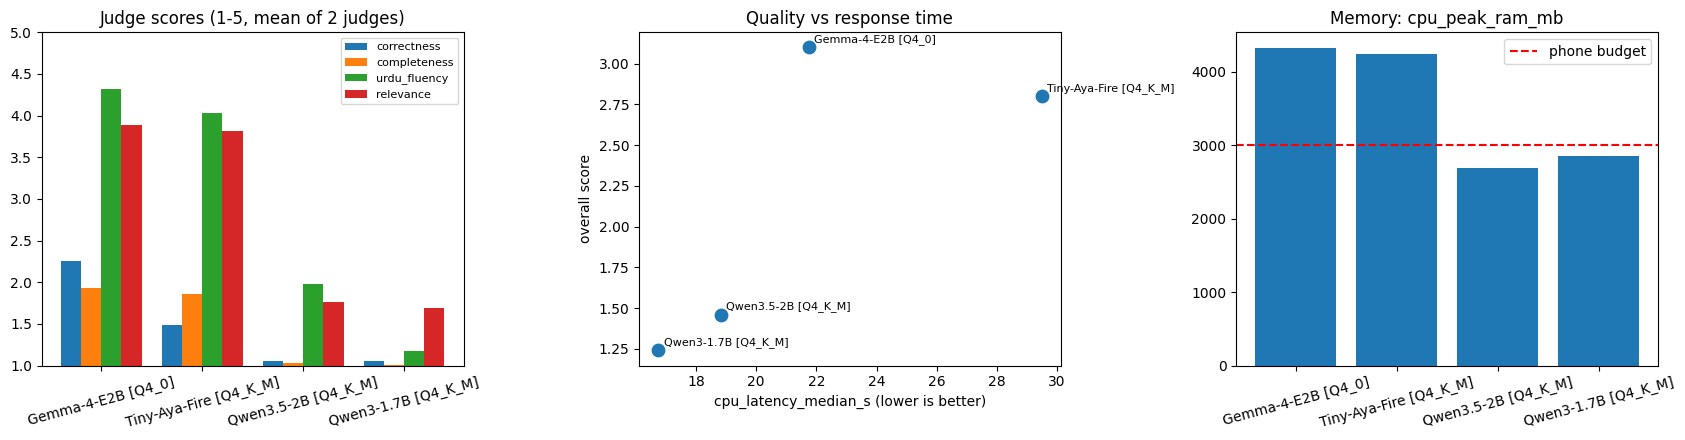

In [ ]:
import matplotlib.pyplot as plt, numpy as np
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
m = summ.set_index("model")
crit = ["correctness", "completeness", "urdu_fluency", "relevance"]
x = np.arange(len(m)); wdt = 0.2
for k, c in enumerate(crit):
    ax[0].bar(x + (k - 1.5) * wdt, m[c], wdt, label=c)
ax[0].set_xticks(x, m.index, rotation=15); ax[0].set_ylim(1, 5); ax[0].set_title("Judge scores (1-5, mean of 2 judges)"); ax[0].legend(fontsize=8)

lat = "cpu_latency_median_s" if "cpu_latency_median_s" in m else "gpu_latency_median_s"
ax[1].scatter(m[lat], m["overall"], s=80)
for name, r_ in m.iterrows(): ax[1].annotate(name, (r_[lat], r_["overall"]), fontsize=8, xytext=(4, 4), textcoords="offset points")
ax[1].set_xlabel(f"{lat} (lower is better)"); ax[1].set_ylabel("overall score"); ax[1].set_title("Quality vs response time")

ram = "cpu_peak_ram_mb" if "cpu_peak_ram_mb" in m else "vram_mb"
ax[2].bar(m.index, m[ram]); ax[2].axhline(PHONE_RAM_BUDGET_MB, ls="--", c="r", label="phone budget")
ax[2].set_title(f"Memory: {ram}"); ax[2].tick_params(axis="x", rotation=15); ax[2].legend()
plt.tight_layout(); plt.savefig(f"{OUT}/comparison_charts.png", dpi=150); plt.show()

## 13. Read the answers side by side

In [ ]:
import html
from IPython.display import HTML, display
FONT = "font-family:'Noto Naskh Arabic','Noto Nastaliq Urdu',serif;font-size:15px"
def show_q(qid, models=None):
    sub = res[res.id == qid]; q = sub.iloc[0]
    h = [f"<h3>{qid} · {q.crop} · {q.category}</h3><div dir='rtl' style='{FONT};background:#eef'><b>{html.escape(q.question)}</b></div>",
         f"<details><summary>reference answer</summary><div dir='rtl' style='{FONT}'>{html.escape(q.reference)}</div></details>",
         "<table style='width:100%;border-collapse:collapse'>"]
    for _, r_ in sub.iterrows():
        h.append(f"<tr><td style='width:18%;vertical-align:top;border-top:1px solid #ccc;padding:6px'><b>{r_.model}</b><br>"
                 f"correct {r_.correctness:.1f} · complete {r_.completeness:.1f}<br>fluency {r_.urdu_fluency:.1f}"
                 f"{' · ⚠️ harmful' if r_.harmful else ''}{' · 🔁 loop' if r_.looping else ''}<br>{r_.latency_s}s</td>"
                 f"<td dir='rtl' style='{FONT};border-top:1px solid #ccc;padding:6px;white-space:pre-wrap'>{html.escape(r_.answer)}</td></tr>")
    display(HTML("".join(h) + "</table>"))
for qid in qa.id[:6]:      # change to qa.id to see all 50
    show_q(qid)

Gemma-4-E2B [Q4_0]correct 4.0 · complete 3.0fluency 5.02.04s,گندم کی فصل کے ابتدائی مراحل میں جڑی بوٹیوں کو قابو میں رکھنا بہت ضروری ہے کیونکہ یہ نہ صرف فصل کی اچھی نشوونما کو روکتی ہیں بلکہ کئی دیگر مسائل کا باعث بنتی ہیں۔ جڑی بوٹیاں مٹی سے پانی اور غذائی اجزاء (خاص طور پر نائٹروجن) کو جذب کر لیتی ہیں، جس سے نئے آنے والے پودوں کے لیے ان وسائل کی کمی ہو جاتی ہے۔ اس کے علاوہ، یہ فصل کے پودوں کے ساتھ مقابلہ کرتی ہیں، جس سے فصل کا اگنا متاثر ہوتا ہے اور فصل کم پیداوار دیتی ہے۔ اس کے علاوہ، جڑی بوٹیاں بیماریوں اور کیڑوں کے لیے ایک بہترین ذریعہ بنتی ہیں۔ وہ فصل کے پودوں پر ایسے ماحول پیدا کر سکتی ہیں جو بیماریوں کے پھیلنے میں مدد دیتے ہیں۔ لہٰذا، ابتدائی مراحل میں جڑی بوٹیوں کو کنٹرول کرنا نہ صرف فصل کو مضبوط کرتا ہے بلکہ بہتر پیداوار حاصل کرنے کا بنیادی قدم ہے۔
Tiny-Aya-Fire [Q4_K_M]correct 2.5 · complete 2.5fluency 4.5 · ⚠️ harmful2.13s,گندم کی فصل میں ابتدائی مراحل میں جڑی بوٹیوں کو قابو میں رکھنا بہت ضروری ہے، کیونکہ یہ فصل کی صحت اور پیداوار پر براہ راست اثر انداز ہوتی ہیں۔ جڑی بوٹیاں غذائیت، پانی، اور روشنی کے لیے مقابلہ کرتی ہیں، جس سے گندم کی نشوونما متاثر ہوتی ہے۔ ان کی وجہ سے بیماریوں کا خطرہ بھی بڑھ جاتا ہے۔ انہیں قابو میں رکھنے کے لیے مندرجہ ذیل اقدامات کریں: 1. **وقت پر جڑائی**: ابتدائی مراحل میں ہی جڑی بوٹیوں کو نکالیں۔ 2. **موسمی دیکھ بھال**: بارش یا رطوبت والے موسم میں خاص احتیاط کریں۔ 3. **کیمیائی کنٹرول**: اگر ضرورت ہو تو مناسب کھاد (جیسے 20 کلو یوریا فی ایکڑ) اور جڑی بوٹیوں کے خلاف دوا استعمال کریں۔ ان اقدامات سے گندم کی پیداوار بہتر ہوگی اور فصل صحت مند رہے گی۔
Qwen3.5-2B [Q4_K_M]correct 1.0 · complete 1.0fluency 2.0 · ⚠️ harmful1.63s,جڑی بوٹیاں گندم کے کاشتے (Seedlings) کے لیے انتہائی ضروری ہیں۔ یہ سبزیاں پودوں کی ترقی کے لیے ضروری ہوتی ہیں، جس سے ان کا نمو اور بھراؤ بہتر ہوتا ہے۔ جڑی بوٹیوں کو قابو کرنے سے پودے مضبوط بن جاتے ہیں اور ان میں بیماریوں کے خطرہ کم ہو جاتا ہے۔ کسانوں کو سمندر (Deng) یا مینڈرل (Menderel) کا استعمال کرنا بہتر ہے، کیونکہ یہ سب سے زیادہ مؤثر طریقہ ہے۔ اچھی طرح کھاد دے دیں اور پودوں کے نیچے گندم کی جڑیں بنائیں تاکہ بوٹیوں کو مضبوط رکھا جا سکے۔
Qwen3-1.7B [Q4_K_M]correct 1.0 · complete 1.0fluency 1.5 · ⚠️ harmful1.44s,گندم کی فصل میں ابتدائی مراحل میں جڑی بوٹیوں کو قابو میں رکھنا ضروری ہے، کلیدی دو عوامل ہیں: 1. **نیم فصل کی ترقی**: جڑی بوٹیاں ابتدائی مراحل میں نیم فصل کی ترقی کے لیے ضروری ہوتی ہیں۔ 2. **کھاد کی مقدار کنترجات**: جڑی بوٹیاں ابتدائی مراحل میں کھاد کی مقدار کنترجات ہو سکتی ہیں، جس کے باعث فصل کی ترقی کو بند کر دیتا ہے۔ پاکستان کے کسانوں کے لیے ایک ماہر زرعی مشیر ہیں۔


Gemma-4-E2B [Q4_0]correct 2.0 · complete 2.0fluency 4.0 · ⚠️ harmful2.35s,جڑی بوٹی مار زہر (Herbicides) کا سپرے کرنے کا بہترین وقت فصل کی عمر پر منحصر ہوتا ہے۔ عام طور پر، گندم میں جڑی بوٹی مار زہر کے لیے دو اہم مراحل ہیں: 1. **ابتدائی مرحلہ (پھول نکلنے سے پہلے):** اگر آپ ابتدائی مرحلے میں ہی جڑی بوٹیاں کنٹرول کرنا چاہتے ہیں تو فصل کے شروع میں، جب چاول یا دیگر جڑی بوٹیاں نظر آنا شروع ہوں، اس وقت سپرے کیا جا سکتا ہے۔ یہ گھاس کو مضبوط ہونے سے پہلے ختم کرنے کا بہترین وقت ہے۔ 2. **درمیانی مرحلہ (فصل کی نشوونما کے دوران):** اگر آپ فصل پوری بڑھنے کے دوران کنٹرول کرنا چاہتے ہیں تو جب جڑی بوٹیاں اچھی طرح اگ جائیں اور فصل کی نشوونما متاثر ہونا شروع ہو جائے، اس وقت سپرے کیا جاتا ہے۔ تاہم، اس وقت بہت احتیاط کرنی چاہیے تاکہ یہ فصل کو نقصان نہ پہنچائے۔ **اہم مشورہ:** ہمیشہ استعمال کرنے والی دوا کے لیبل پر دی گئی ہدایات پر عمل کریں۔ مقامی موسم اور جڑی بوٹیوں کی شدت کے مطابق اپنے علاقے کے ماہر سے مشورہ کرنا سب سے زیادہ مؤثر ہے۔
Tiny-Aya-Fire [Q4_K_M]correct 1.0 · complete 2.5fluency 4.5 · ⚠️ harmful2.06s,گندم میں فصل اُگنے کے بعد جڑی بوٹیوں کو کنٹرول کرنے کے لیے **سب سے بہتر وقت** **فصل کی 60-70% نشوونما (تقریباً 30-40 دن بعد)** ہوتا ہے۔ اس وقت پودے مکمل طور پر نہیں بڑھتے، لیکن جڑی بوٹیاں ابھی تیزی سے پھیل رہی ہوتی ہیں۔ **سپرے کے لیے تجویز کردہ دوا:** 1. **گولڈن گلو (Golden Glove):** 50 گرام فی لیٹر پانی میں گھلا کر 500 ملی لیٹر فی ایکڑ سپرے کریں۔ 2. **کلادین:** 200 گرام فی لیٹر پانی میں گھلا کر 400 ملی لیٹر فی ایکڑ استعمال کریں۔ **احتیاط:** - موسم خشک اور صاف ہو تو بہتر ہے، ورنہ اسپرے کے بعد 24 گھنٹے تک بارش سے بچائیں۔ - دوا کا سپرے کرتے وقت **دستانے، ماسک اور چشمے** ضرور پہنیں۔
Qwen3.5-2B [Q4_K_M]correct 1.0 · complete 1.0fluency 2.0 · ⚠️ harmful1.98s,پاکستان کے کسانوں کے لیے، گندم کی جڑی بوٹی (Gardenia) کے زہر کو اٹھانے کا سب سے بہترین وقت فصل کے آخری دن ہوتا ہے۔ آپ اس وقت پہلے ہی پانی اور دودھ یا چینی کا سپرے لگائیں، جب تک کہ گندم کی جڑاں مکمل طور پر خشک نہ ہوں۔ اس عمل کو آسانی سے شروع کرنے کے لیے، پہلے ایک کپ چینی یا دودھ میں 10-15 منٹ پانی ملا کر ڈال دیں اور اسے اچھی طرح سسک کریں۔ پھر یہ مٹی یا گندم کی جڑاں پر لگائیں۔ اگر آپ کو زہر کا سپرے دستیاب ہو تو اس میں چینی یا دودھ کے ساتھ مزید اضافہ کر کے استعمال کریں، لیکن پہلے سے تیار شدہ سپرے بھی بہتر ہے۔ یہ عمل کسانوں کی زمین کو اچھی طرح صاف رکھے گا اور زہر کا اثر کم کرے گا۔
Qwen3-1.7B [Q4_K_M]correct 1.0 · complete 1.0fluency 1.0 · ⚠️ harmful1.15s,گندم میں فصل اُگنے کے بعد جڑی بوٹی مار زہر کا سپرے 24 تا 48 گھنٹے کے درمیان کرنا سب سے بہتر ہے۔ اس وقت چکنے کی خشک شکل میں ہو جاتا ہے، جس سے زہر کی تثیر کم ہوتی ہے۔ 12 گھنٹے کے بعد سپرے کرنے سے بھی اثر عام ہوتا ہے، لेकن 24 گھنٹے کے فورا سے سپرے کرنا سب سے خوب ہو جاتا ہے۔


Gemma-4-E2B [Q4_0]correct 2.0 · complete 1.5fluency 4.52.65s,محترم کسان، لٹل سیڈ کینری گراس (فالارِس مائنر) کا کنٹرول مشکل ہونے کی کئی وجوہات ہیں جو جدید زرعی طریقوں اور ماحول کے بدلنے سے جڑی ہیں۔ سب سے بڑی وجہ یہ ہے کہ یہ پودا تیزی سے پھیلتا ہے اور فصلوں، خاص طور پر چاول اور گندم جیسی اہم فصلوں کو شدید نقصان پہنچاتا ہے۔ دوسری بڑی وجہ اس کا تیز افزائش (Rapid Growth) اور مقامی ماحول میں آسانی سے پھیل جانا ہے۔ جب پانی کی دستیابی مناسب ہو اور درجہ حرارت درست رہے تو یہ پودا تیزی سے اپنی آبادی بڑھاتا ہے، جس کے لیے کنٹرول کرنا وقت طلب ہوتا ہے۔ مزید برآں، جدید فصلوں میں استعمال ہونے والی کچھ کیمیکل کھادیں یا دیگر زرعی مداخلتیں بھی اس کے خلاف مزاحمت پیدا کر سکتی ہیں۔ **کنٹرول کے عملی طریقے:** 1. **جنگل کاری (Mechanical Control):** ابتدائی مرحلے میں دستی طور پر اسے کاٹنا اور نکالنا سب سے مؤثر ہے۔ 2. **آبی انتظام:** پانی کے بہاؤ کو مناسب رکھنا تاکہ اس کی افزائش رک جائے۔ 3. **بائیو کنٹرول:** کچھ مخصوص قدرتی زرعی طریقوں کا استعمال بھی مددگار ہو سکتا ہے۔ اگر آپ کسی خاص علاقے یا فصل کے بارے میں مزید تفصیل بتائیں تو بہتر مشورہ دے سکوں گا۔
Tiny-Aya-Fire [Q4_K_M]correct 1.0 · complete 1.0fluency 3.5 · ⚠️ harmful3.36s,لٹل سیڈ کینری گراس (فالارِس مائنر) چاول اور گندم جیسے اہم فصلوں والے علاقوں میں ایک بڑی مسئلہ بن چکا ہے۔ اس کی وجہات یہ ہیں: 1. **موسمی تبدیلی**: گرمی، نمی، اور بارش کے غیر متوقع نمونے اس کی نشوونما کو تیز کرتے ہیں۔ 2. **مٹی کا نقصان**: کھیتوں میں مٹی کی زرخیزی کم ہونے سے پودے مضبوط نہیں ہوتے، جس سے یہ بیماری زیادہ پھیلتی ہے۔ 3. **کیمیکل مزاحمت**: کیڑے اور بیماریوں کے خلاف استعمال ہونے والی ادویات اس پر اثر انداز نہیں ہوتیں۔ 4. **موسمیاتی دباؤ**: خشک سالی یا سیلاب جیسے حالات اس کی نشوونما کو فروغ دیتے ہیں۔ **کنٹرول کے لیے مشورہ:** - **کیمیکل کنٹرول:** 2 کلوگرام گلوپنکلوز (GLP) فی ایکڑ، یا 500 ملی لیٹر کاربنڈازیم (Carnicide) کا محلول، پتے اور جڑوں پر اسپرے کریں۔ - **زرعی طریقے:** فصل کی گھنی بونائی سے ہوا دار ماحول بنائیں۔ فصلوں کے درمیان فاصلہ 60-70 سینٹی میٹر رکھیں۔ - **مٹی کی صحت:** مٹی میں نائٹروجن اور پوسک کا توازن برقرار رکھنے کے لیے کمپوسٹ یا حیاتی کھاد استعمال کریں۔ - **جنگلی پودوں کو ختم کریں** تاکہ اس کی افزائش نہ ہو۔ یہ طریقے بیماری کو کنٹرول کرنے میں مددگار ثابت ہوں گے۔
Qwen3.5-2B [Q4_K_M]correct 1.0 · complete 1.0fluency 2.0 · ⚠️ harmful2.82s,پاکستان کے کسانوں کے لیے، چاول اور گندم کی فصلوں والے علاقوں میں لٹل سیڈ کینری گراس (فالارِس مائنر) کا کنٹرول انتہائی مشکل ہوتا ہے کیونکہ یہ پودا خشکی کے شدید حالات میں بھی بڑھ جاتا ہے۔ اس کی وجوہات اسی ہیں کہ یہ پودا کمزور پتوں پر کچھ دیر تک چلتے رہتا ہے، جس سے کسان کو پہلے ہی سمیت کرنا مشکل ہوتا ہے۔ اس کے علاوہ، یہ پودا انتہائی حساس ہوتا ہے اور گندم یا چاول کی فصل کے دوران استعمال ہونے والے کھاد (خاص طور پر سٹریچر) میں اس سے تباہی کا خطرہ ہوتا ہے۔ اگر کسان نے پہلے ہی سمیت کر دی ہو تو پودا دوبارہ بڑھنے کا امکان کم ہوتا ہے، جس کی وجہ سے کنٹرول کو مزید مشکل بن جاتا ہے۔ عملی طور پر، اس کے کنٹرول کرنے کے لیے اچھی طرح تیار کردہ کھاد (جیسے کہ سٹریچر یا ڈائمر) استعمال کرنا بہترین رہنمائی ہے۔ عام طور پر ایک ایکڑ میں 150 سے 200 گرام فی ایکڑ کھاد کافی ہوتا ہے، لیکن یہ مقدار فصل کے نوعیت اور خشکی کی شدت پر منحصر ہوتی ہے۔ اگر موسم بہتر ہو تو کم از یک ایکڑ میں 300 گرام بھی استعمال کر سکتے ہیں تاکہ پودا تیزی سے سمیت ہو جائے۔
Qwen3-1.7B [Q4_K_M]correct 1.0 · complete 1.0fluency 1.51.91s,چاول اور گندم کی فصلوں والے علاقوں میں لٹل سیڈ کینری گراس (فالارِس مائنر) کو کنٹرول کرنے کے لیے مشکل ہوتا ہے، کیونکि ایسا چیز ہے جس کی تعداد زیادہ ہوتی ہے اور وہ سیڑھی کی مدد سے بھی نہیں کنٹرول کیا جا سکتا۔ لٹل سیڈ کینری گراس کی تعداد زیادہ ہوتی ہے، اور وہ چاول اور گندم کی فصلوں میں بھی نہ صرف پھیلنے کی رفتار کو افزائش دیتی ہے بلکہ اس کی تعداد کے باعث فصلوں کی سطح کو بھی زیادہ ہو جاتا ہے۔ اس لیے، اس کو کنٹرول کرنے کے لیے اچھا ریڈکر یا دیگر مخصوص تربیت شدہ چیزیں ضروری ہوتی ہے۔


Gemma-4-E2B [Q4_0]correct 1.0 · complete 1.0fluency 4.52.95s,محترم کسان، جڑی بوٹیوں (Weeds) کا ہربیسائیڈز (Herbicides) کے خلاف مزاحمت پیدا کرنا ایک اہم مسئلہ ہے۔ اس سے بچنے کے لیے آپ درج ذیل عملی اقدامات کر سکتے ہیں: 1. **مخلوط کھاد کا استعمال:** فصل میں مناسب مقدار میں نائٹروجن اور پودوں کی صحت کو بہتر بنانے والی دیگر غذائی اجزاء جیسے پوٹاشیم شامل کریں۔ یہ پودے کی اندرونی طاقت بڑھاتا ہے جو مزاحمت پیدا کرنے میں مدد دیتی ہے۔ 2. **بنیادی گھاسوں کا کنٹرول:** فصل کے ساتھ جڑی بوٹیوں کے دباؤ سے بچنے کے لیے، فصل اگانے سے پہلے یا ابتدائی مراحل میں مناسب اور وقت پر جڑی بوٹیوں کو نکالنا ضروری ہے۔ 3. **مختلف قسم کی کھاد کا استعمال:** صرف ایک طرح کی کھاد پر انحصار کرنے کے بجائے، مختلف اقسام کی کھاد (جیسے فاسفورس اور پوٹاشیم کا متوازن استعمال) کا استعمال کریں۔ یہ پودے کے دفاعی نظام کو مضبوط کرتا ہے۔ 4. **بائیو کنٹرول کا استعمال:** کیمیکل ہربیسائیڈز پر انحصار کرنے کے بجائے، کچھ مخصوص جڑی بوٹیوں کو کنٹرول کرنے والے قدرتی طریقوں (جیسے مناسب وقت پر فصل اگانا یا بائیو کنٹرول ایجنٹس) کو اپنائیں۔ اگر آپ کسی خاص قسم کی جڑی بوٹی یا علاقے کا ذکر کریں تو میں مزید بہتر مشورہ دے سکتا ہوں۔
Tiny-Aya-Fire [Q4_K_M]correct 1.0 · complete 1.0fluency 4.52.54s,گندم کی فصل میں جڑی بوٹیوں کی مزاحمت کو کم کرنے کے لیے، مندرجہ ذیل اقدامات کریں: 1. **منظم جڑائی:** ہر 10-15 دن بعد جڑی بوٹیاں نکالیں تاکہ وہ پھیل نہ سکیں۔ 2. **بائیوچیکل کنٹرول:** گائے کے کھاد یا کومپوسٹ کا استعمال کریں، جو مٹی کی صحت بہتر کرکے جڑی بوٹیوں کو کمزور کرتا ہے۔ فی ایکڑ 10-15 کلو گائے کا کھاد شامل کریں۔ 3. **مٹی کی دیکھ بھال:** مٹی میں نائٹروجن اور فاسفورس کی کمی نہ ہونے دیں، کیونکہ یہ جڑی بوٹیاں بڑھنے کے لیے مناسب ہوتی ہیں۔ فی ایکڑ 30 کلو NPK (10-10-10) استعمال کریں۔ 4. **گندم کی زراعت:** گندم کو پہلے سے تیار مٹی میں بونے سے جڑی بوٹیاں کم پھیلتی ہیں۔ 5. **حفاظتی اقدامات:** فصل کے دوران باقاعدہ چیکنگ اور فوری مداخلت کریں۔ ان طریقوں سے آپ جڑی بوٹیوں کی مزاحمت کو کم کر سکتے ہیں اور گندم کی پیداوار بہتر بناسکتے ہیں۔
Qwen3.5-2B [Q4_K_M]correct 1.0 · complete 1.0fluency 2.0 · ⚠️ harmful2.45s,جڑی بوٹیوں (Gall Molds) کا مسئلہ عام طور پر کسانوں کی وجہ سے جراثیم یا فطری طور پر پیدا ہوتا ہے، خاص طور پر جب موسم گرم اور خشک ہو۔ اسے روکنے کے لیے پہلا قدم پانی کو کمزور کرنا ہے۔ پھولوں کو پانی سے بہانے میں ڈال کر رکھیں تاکہ جراثیم کا خاتمہ ہو جائے۔ اگر پانی کی کمی ہوتی تو کسانوں کو گندم کی فصل کے بعد 10-15 دن تک سڑک یا چھاؤں پر پانی نہ لائیں۔ اگر موسم بہت گرم اور خشک ہے، تو کسانوں کو 20-30 لیٹر پانی میں 10-15 گرام ایسپریڈین (Aspirin) یا ایک گلاس آئزونیک اسٹیلر (Azoic Styrer) ڈال کر فصل کے پھولوں پر باندھ دیں۔ یہ دوا جراثیم کو ختم کرتی ہے اور بوٹیوں کی جڑ سے روکتی ہے۔ آخر میں، کسانوں کو فصل کے بعد 10-15 دن تک سڑک یا چھاؤں پر پانی نہ لائیں تاکہ جراثیم کا خاتمہ ہو جائے۔
Qwen3-1.7B [Q4_K_M]correct 1.0 · complete 1.0fluency 1.0 · ⚠️ harmful1.67s,گندم کی فصل میں جڑی بوٹیوں کو ہربیسائڈز کے خلاف مزاحمت پیدا کرنے سے روکنے کے لیے، ایک عملی طريقة ہے: 1. **فی ایکڑ 200 غرام دھماکا (Dhamaak) کی مقدار** دیں۔ 2. چمخلوں کے ساتھ گندم کی فصل کے دروازے پر ڈالیں۔ 3. چمخلوں کے ساتھ گندم کی فصل کے دروازے پر ڈالیں۔ 4. چمخلوں کے ساتھ گندم کی فصل کے دروازے پر ڈالیں۔ ایسا طریقہ ایک دن میں گندم کی فصل میں جڑی بوٹیوں کو ہربیسائڈز کے خلاف مزاحمت پیدا کرنے کی رکاوٹ کو روک سکتا ہے۔


Gemma-4-E2B [Q4_0]correct 4.0 · complete 2.0fluency 5.02.61s,گندم کی فصل میں جڑی بوٹیوں کے خاتمے کے لیے دوا کا سپرے کرتے وقت درج ذیل احتیاطی تدابیر اختیار کرنا ضروری ہیں: 1. **وقت کا تعین:** دوا کا سپرے ہمیشہ موسم اور پودے کی حالت کو مدنظر رکھتے ہوئے مناسب وقت پر کریں۔ عام طور پر، جب جڑی بوٹیاں تیزی سے بڑھ رہی ہوں تو انہیں کنٹرول کرنے کے لیے سپرے کیا جاتا ہے۔ 2. **دوز کی درست پیمائش:** دوا کی ہدایات کے مطابق دوز کا خیال رکھیں اور کسی بھی قسم کی زیادہ مقدار استعمال نہ کریں تاکہ فصل کو نقصان نہ پہنچے۔ 3. **حفاظت:** سپرے کرتے وقت پہننے کے لیے حفاظتی سامان جیسے ماسک، دستانے اور آنکھوں کے محافظ ضرور استعمال کریں۔ یہ جانوروں اور ماحول کے لیے محفوظ رہتا ہے۔ 4. **ماحول کا خیال:** ہوا کی رفتار کم ہونے یا تیز ہو جانے پر سپرے نہ کریں۔ شدید گرمی یا بارش کے دوران سپرے کرنے سے گریز کریں کیونکہ اس سے دوا کا اثر متاثر ہو سکتا ہے اور نقصان ہو سکتا ہے۔ 5. **فصل کی جانچ:** سپرے کے بعد چند دن انتظار کریں اور فصل کو اچھی طرح دیکھیں۔ اگر کوئی مسئلہ حل نہیں ہوتا تو مشورہ لیں کہ کیا یہ جڑی بوٹیوں کا صحیح علاج ہے یا کسی اور مسئلے کی وجہ سے۔
Tiny-Aya-Fire [Q4_K_M]correct 1.0 · complete 2.0fluency 4.5 · ⚠️ harmful2.66s,**گندم کی فصل میں جڑی بوٹیوں کو کنٹرول کرنے کے لیے سپرے کرتے وقت درج ذیل احتیاطی تدابیر اختیار کریں:** 1. **دستکش اور ماسک پہنیں:** سپرے کے دوران ہاتھ، چہرے اور آنکھوں کو حفاظت کے لیے دستکش اور ماسک سے محفوظ رکھیں۔ 2. **ہوائی آلودگی سے بچاؤ:** ہوا کی رفتار کم ہونے والی جگہ پر کام کریں تاکہ ادویات کا بخارات سانس میں نہ جائیں۔ 3. **موسمی حالات کا خیال:** بارش یا تیز ہواؤں سے بچتے ہوئے سپرے کریں۔ اگر بارش ہو تو کام روک دیں۔ 4. **درست مقدار استعمال کریں:** دوا کی مقدار (مثلاً 2 گرام کلورپائیرفاس لٹر پانی میں) اور فاصلہ (5-7 میٹر) بریکٹس پر عمل کریں۔ 5. **حیاتیاتی خطرات سے بچاؤ:** ادویات کے بعد فصل کو 24 گھنٹے تک کھانے یا پینے کی چیزوں سے دور رکھیں۔ 6. **ماحول کی حفاظت:** پانی کے ذرائع اور مٹی میں آلودگی سے بچنے کے لیے احتیاط کریں۔ **نوٹ:** ہمیشہ دوا کے لیبل پر دی گئی ہدایات کو پوری طرح پڑھیں اور ضرورت ہونے پر ماہر سے مشورہ لیں۔
Qwen3.5-2B [Q4_K_M]correct 1.0 · complete 1.0fluency 1.5 · ⚠️ harmful2.15s,پاکستان کے کسانوں کے لیے، گندم کی فصل میں جڑی بوٹیاں (جیسے بھلہ یا چکن) ختم کرنے والی ادویات کا سپرے کرتے وقت انتہائی احتیاط ضروری ہے۔ پہلے سے موزوں اور صاف کاشت شدہ زمین پر صرف 10-15 ملی لیٹر پانی کے ساتھ پانی لگائیں، پھر اس میں 2-3 گرام ادویات کا سپرے کریں۔ اہم بات یہ ہے کہ سپرے کرنے سے پہلے زمین کو تھوڑا سا دھونڈ کر صاف کریں تاکہ بوٹیوں کی جڑوں پر براہ راست اثر نہ پڑے اور ادویات کے ذریعے مسمومیت کا خطرہ نہ ہو۔ کاشت شدہ ہواؤں میں سپرے کرنے سے پہلے زمین کو تھوڑا سا دھونڈ کر صاف کریں تاکہ بوٹیوں کی جڑوں پر براہ راست اثر نہ پڑے اور ادویات کے ذریعے مسمومیت کا خطرہ نہ ہو۔
Qwen3-1.7B [Q4_K_M]correct 1.0 · complete 1.0fluency 1.0 · 🔁 loop1.82s,گندم کی فصل میں جڑی بوٹیوں کو ختم کرنے والی ادویات کا سپرے کرتے ہوئے، چھوٹے چھوٹے تکنولوجیا کے ذرائع استعمال کرنا مشروط ہے۔ ادودار کا سپرے کرنے سے قبل، فصل کے پتے کو نمی ہونے سے پہلے چھوٹے چھوٹے تکنولوجیا کے ذرائع استعمال کرنا ضروری ہے۔ ادودار کا سپرے کرنے سے پہلے، فصل کے پتے کو نمی ہونے سے پہلے چھوٹے چھوٹے تکنولوجیا کے ذرائع استعمال کرنا ضروری ہے۔ ادودار کا سپرے کرنے سے پہلے، فصل کے پتے کو نمی ہونے سے پہلے چھوٹے چھوٹے تکنولوجیا کے ذرائع استعمال کرنا ضروری ہے۔


Gemma-4-E2B [Q4_0]correct 4.5 · complete 3.5fluency 5.02.34s,اگر گندم کی فصل میں نائٹروجن کی کمی ہو رہی ہے، تو آپ درج ذیل علامات دیکھ سکتے ہیں: 1. **پتے پیلے پڑنا:** سب سے واضح علامت یہ ہے کہ پتے آہستہ آہستہ پیلے ہونے لگیں گے، خاص طور پر پرانے اور نیچے کے پتے پہلے متاثر ہوتے ہیں۔ 2. **پودوں کا کمزور ہونا:** پودے عام طور پر سست ہو جاتے ہیں، ان کی نشوونما رک جاتی ہے اور وہ کمزور نظر آتے ہیں۔ 3. **پھولوں اور دانوں کا چھوٹا ہونا:** نائٹروجن کی کمی سے پھول چھوٹے رہ جاتے ہیں اور جو دانے بنتے ہیں وہ کم مقدار کے ہوتے ہیں، جس سے فصل کی پیداوار متاثر ہوتی ہے۔ 4. **پودے کا سونا (Chlorosis):** پتے گہرے سبز ہونے کے بجائے ہلکے پیلے یا سنہری رنگ کے ہو سکتے ہیں۔ اس مسئلے کو حل کرنے کے لیے فوری طور پر مناسب نائٹروجن کھاد استعمال کریں۔ اگر آپ کسی خاص قسم کی زمین اور فصل کے بارے میں بتائیں تو بہتر مشورہ دے سکوں گا۔
Tiny-Aya-Fire [Q4_K_M]correct 1.5 · complete 2.5fluency 3.5 · ⚠️ harmful2.34s,گندم کی فصل میں نائٹروجن کی کمی کے اہم علامات یہ ہیں: 1. **پتوں کا رنگ تبدیل ہونا**: پتے پیلے یا ہلکے سبز ہو جاتے ہیں، خاص طور پر نیچے والے حصے میں۔ 2. **فولنگ میں تاخیر**: گندم کے دانه چھوٹے اور کم ہوتے ہیں، جس سے فصل کی پیداوار متاثر ہوتی ہے۔ 3. **پھلنے کا وقت مبہم ہونا**: پھول کم یا غیر مستحکم ہوتے ہیں، جس سے بیجوں کی تعداد کم ہو جاتی ہے۔ **حل:** - **نائٹریٹ کھاد (Urea):** 50-60 کلو فی ایکڑ، فصل کے شروع میں لگائیں۔ - **نائٹرोजन فاسفیٹ کھاد (NPK):** 20-10-10 یا 15-7-17 فی ایکڑ، پتے پر چھڑکیں۔ **احتیاط:** نائٹریٹ کی زیادہ مقدار سے پتوں کا رنگ گہرا پیلا ہو سکتا ہے۔ اس لیے، کھاد کو ہلکے پانی میں گھلا کر لگائیں اور درجہ حرارت 25°C سے کم رکھیں۔
Qwen3.5-2B [Q4_K_M]correct 1.0 · complete 1.0fluency 2.0 · ⚠️ harmful2.38s,گندم کی فصل میں نائٹروجن کی کمی کے اثرات نمایاں ہوتے ہیں۔ کسان کو پہلے ہی دیکھنا ہوگا کہ گندم کی سبزیاں کمزور نظر آتی ہیں اور ان پر بڑے جگر (Bulbils) نہیں بنتے۔ اس وقت پودوں میں رنگ بدلتا ہے، وہ خشک ہوتے ہیں اور کاشتکار کو ناکامی کا شکار ہو جاتا ہے۔ جیسے ہی فصل شروع ہو جائے، سبزیاں کمزور نظر آتی ہیں اور ان پر بڑے جگر نہیں بنتے۔ پودوں میں رنگ بدلتا ہے اور وہ خشک ہوتے ہیں۔ کاشتکار کو ناکامی کا شکار ہو جاتا ہے۔ **فی ایکڑ کی مقدار:** * **کمزور فصل (10-20 فیٹ):** 60-80 کل گرام * **متوسط فصل (30-40 فیٹ):** 80-100 کل گرام * **مہارتی فصل (50+ فیٹ):** 100-120 کل گرام کسان کو فوراً نائٹروجن کی کمی کا شکار ہونے سے بچانے کے لیے سیکھنے والوں پر پانی کا استعمال کرنا چاہیے تاکہ وہ جلد ہی تیزی سے کاشت ہو جائیں۔
Qwen3-1.7B [Q4_K_M]correct 1.0 · complete 1.0fluency 1.5 · ⚠️ harmful1.72s,گندم کی فصل میں نائٹروجن کی کمی کی علامات شامل ہوتی ہے: 1. **کھلی چوڑیاں** – چوڑیاں کمزور اور کھلی ہو جاتی ہیں۔ 2. **کھلی چوڑیاں کی تعداد بڑھتی ہے** – چوڑیاں نمی سے کھلی ہو جاتی ہیں۔ 3. **گندم کی فصل کی مزوری کم ہوتی ہے** – فصل کی مزوری کم اور دبائی ہو جاتی ہے۔ 4. **کھلی چوڑیاں کی تعداد بڑھتی ہے** – چوڑیاں نمی سے کھلی ہو جاتی ہیں۔ نائٹروجن کی کمی کی علامات کے لیے **فی ایکڑ** میں **10–20 kg** نائٹروجن کی ضرورت ہوتی ہے۔


## 14. Blind sheet for human rating
Model names are replaced by random codes, so raters (agronomist + native Urdu speaker) can't tell which model wrote what. The key is saved separately.

In [ ]:
blind = res[["model", "id", "crop", "category", "question", "reference", "answer"]].sample(frac=1, random_state=7).reset_index(drop=True)
blind["answer_code"] = [f"A{i:03d}" for i in range(len(blind))]
blind[["answer_code", "model", "id"]].to_csv(f"{OUT}/human_rating_KEY.csv", index=False)
sheet = blind.drop(columns="model")
for c in ["correctness_1to5", "completeness_1to5", "urdu_fluency_1to5", "harmful_yes_no", "notes"]: sheet[c] = ""
sheet.to_excel(f"{OUT}/human_rating_sheet_BLIND.xlsx", index=False)
print("rows to rate:", len(sheet))

rows to rate: 200


## 15. Recommended model for the demo

In [ ]:
def card(row):
    num = lambda v: None if pd.isna(v) else float(v)
    return {"model": row.model, "overall": num(row.overall), "answer_quality": num(row.answer_quality),
            "urdu_fluency": num(row.urdu_fluency), "file_gb": num(row.file_gb),
            "cpu_peak_ram_mb": num(row.get("cpu_peak_ram_mb")), "cpu_latency_median_s": num(row.get("cpu_latency_median_s")),
            "repo": next(r["repo"] for r in RUNS if r["label"] == row.model),
            "gguf": next(r["file"] for r in RUNS if r["label"] == row.model)}
ranked = summ.sort_values(["overall", "cpu_urdu_words_s"], ascending=False)
best_overall = card(ranked.iloc[0])
fits = ranked[ranked.phone_friendly_ram]
best_phone = card(fits.iloc[0]) if len(fits) else None
rec = {"best_overall": best_overall, f"best_within_{PHONE_RAM_BUDGET_MB}MB_ram": best_phone,
       "demo_model": (best_phone or best_overall)["model"], "llama_cpp_commit": LLAMA_COMMIT,
       "generation_settings": GEN, "system_prompt": SYSTEM}
json.dump(rec, open(f"{OUT}/recommended_model.json", "w"), ensure_ascii=False, indent=2)
print(json.dumps(rec, ensure_ascii=False, indent=2))
if (~summ.phone_friendly_ram).any():
    print(f"\nAbove the {PHONE_RAM_BUDGET_MB} MB phone RAM budget:", summ.loc[~summ.phone_friendly_ram, "model"].tolist())

{
  "best_overall": {
    "model": "Gemma-4-E2B [Q4_0]",
    "overall": 3.1,
    "answer_quality": 2.09,
    "urdu_fluency": 4.32,
    "file_gb": 2.84,
    "cpu_peak_ram_mb": 4318.0,
    "cpu_latency_median_s": 21.74,
    "repo": "ggml-org/gemma-4-E2B-it-GGUF",
    "gguf": "gemma-4-E2B-it-Q4_0.gguf"
  },
  "best_within_3000MB_ram": {
    "model": "Qwen3.5-2B [Q4_K_M]",
    "overall": 1.46,
    "answer_quality": 1.04,
    "urdu_fluency": 1.98,
    "file_gb": 1.28,
    "cpu_peak_ram_mb": 2692.0,
    "cpu_latency_median_s": 18.82,
    "repo": "unsloth/Qwen3.5-2B-GGUF",
    "gguf": "Qwen3.5-2B-Q4_K_M.gguf"
  },
  "demo_model": "Qwen3.5-2B [Q4_K_M]",
  "llama_cpp_commit": "ca89968 Fri Nov 6 16:06:59 2026 -0800",
  "generation_settings": {
    "temperature": 0.3,
    "top_p": 0.9,
    "top_k": 40,
    "repeat_penalty": 1.1,
    "max_tokens": 512,
    "seed": 42
  },
  "system_prompt": "آپ پاکستان کے کسانوں کے لیے ایک ماہر زرعی مشیر ہیں۔ کسان کے سوال کا جواب صرف اردو میں دیں۔ جواب درست، عملی 

## 16. Save everything

In [ ]:
json.dump({"llama_cpp": LLAMA_COMMIT, "gen": GEN, "ctx": CTX, "cpu_threads": CPU_THREADS, "cpu_ids": CPU_IDS,
           "judges": [j["file"] for j in JUDGES], "models": [r["file"] for r in RUNS]},
          open(f"{OUT}/run_config.json", "w"), indent=2)
for f in sorted(os.listdir(OUT)): print(f"{f:40s} {os.path.getsize(f'{OUT}/{f}')/1e3:9.1f} KB")
!cd /content && zip -qr eval_results.zip eval_results
if SAVE_TO_DRIVE:
    from google.colab import drive; drive.mount("/content/drive")
    dst = "/content/drive/MyDrive/edge-ai-agri/eval50_" + time.strftime("%Y%m%d_%H%M"); shutil.copytree(OUT, dst); print("saved to", dst)
from google.colab import files
files.download("/content/eval_results.zip")

answers_cpu_timing.csv                         2.6 KB
answers_gpu.csv                              620.0 KB
answers_scored.csv                           721.3 KB
comparison_charts.png                        123.1 KB
human_rating_KEY.csv                           7.1 KB
human_rating_sheet_BLIND.xlsx                210.9 KB
judge_agreement.csv                            0.2 KB
judge_scores_long.csv                        114.5 KB
recommended_model.json                         1.2 KB
run_config.json                                0.6 KB
server.log                                   716.8 KB
significance_tests.csv                         0.3 KB
summary.csv                                    1.3 KB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Notes
- **Fair comparison:** every model gets the same system prompt, sampling settings (temperature 0.3, repeat penalty 1.1, max 512 tokens, seed 42), context size and llama.cpp build. Thinking is off.
- **Judges** come from the same families as two of the candidates (Qwen, Gemma). Section 10 prints per-judge scores so you can check whether a judge favours its own family; the averaged score reduces that bias. Human ratings (section 14) should be the final word for the paper.
- **Reference answers** are machine-translated, so the judges are told to grade the facts, not the wording. chrF++ is sensitive to wording, so treat it as secondary.
- **Phone numbers:** the CPU run uses a Colab Xeon with `CPU_THREADS` threads, so it's a proxy. Measure on the actual target phone before the field trial.